#**Connect drive**

In [2]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [3]:

import os
drive.mount('/content/drive')

PROJECT_DIR = "/content/drive/MyDrive/thesis_DR"
os.makedirs(PROJECT_DIR, exist_ok=True)

print(PROJECT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/thesis_DR


#**Load Dataset**

In [8]:
from pathlib import Path

DATA_DIR = Path("/content/APTOS")
CSV_PATH = DATA_DIR / "train.csv"
IMAGE_DIR = DATA_DIR / "train_images"

# Check whether dataset is already fully available
image_count = len(list(IMAGE_DIR.glob("*.png"))) if IMAGE_DIR.exists() else 0

if CSV_PATH.exists() and image_count == 3662:
    print("APTOS already ready.")
    print("CSV:", CSV_PATH)
    print("Images:", image_count)
    print("Skipping download and unzip.")

else:
    print("APTOS not complete. Downloading...")

    !mkdir -p ~/.kaggle
    !cp kaggle.json ~/.kaggle/kaggle.json
    !chmod 600 ~/.kaggle/kaggle.json

    # Download only if ZIP does not already exist
    if not (DATA_DIR / "aptos2019-blindness-detection.zip").exists():
        !kaggle competitions download -c aptos2019-blindness-detection -p /content/APTOS

    # -o = overwrite automatically, NO questions
    !unzip -q -o /content/APTOS/aptos2019-blindness-detection.zip -d /content/APTOS

    image_count = len(list(IMAGE_DIR.glob("*.png")))

    print("CSV:", CSV_PATH.exists())
    print("Images:", image_count)

APTOS not complete. Downloading...
100% 9.51G/9.51G [08:05<00:00, 21.0MB/s]

CSV: True
Images: 3662


In [5]:
from pathlib import Path

CSV_PATH = Path("/content/APTOS/train.csv")
IMAGE_DIR = Path("/content/APTOS/train_images")

print("CSV:", CSV_PATH.exists())
print("Images:", len(list(IMAGE_DIR.glob("*.png"))))

CSV: False
Images: 0


#**Data Audit**

In [18]:
import pandas as pd
from pathlib import Path

CSV_PATH = Path("/content/APTOS/train.csv")
IMAGE_DIR = Path("/content/APTOS/train_images")

df = pd.read_csv(CSV_PATH)

# Image files
image_files = list(IMAGE_DIR.glob("*.png"))

csv_ids = set(df["id_code"].astype(str))
image_ids = {p.stem for p in image_files}

# Basic checks
print("========== APTOS RAW DATA AUDIT ==========")

print("\nTotal CSV rows:", len(df))
print("Total image files:", len(image_files))

print("\nMissing id_code:", df["id_code"].isna().sum())
print("Missing diagnosis:", df["diagnosis"].isna().sum())
print("Duplicate id_code:", df["id_code"].duplicated().sum())

print("\nUnique diagnosis labels:", sorted(df["diagnosis"].unique()))

invalid_labels = df[~df["diagnosis"].isin([0, 1, 2, 3, 4])]
print("Invalid labels:", len(invalid_labels))

print("\nCSV records without image:", len(csv_ids - image_ids))
print("Images without CSV label:", len(image_ids - csv_ids))

# Grade distribution
grade_counts = df["diagnosis"].value_counts().sort_index()

print("\n========== ORIGINAL 5-GRADE DISTRIBUTION ==========")

for grade, count in grade_counts.items():
    percentage = count / len(df) * 100
    print(f"Grade {grade}: {count} ({percentage:.2f}%)")

# Binary task
df["binary_label"] = (df["diagnosis"] >= 2).astype(int)

binary_counts = df["binary_label"].value_counts().sort_index()

print("\n========== BINARY DISTRIBUTION ==========")

print(
    f"Non-referable (Grade 0-1): "
    f"{binary_counts[0]} "
    f"({binary_counts[0]/len(df)*100:.2f}%)"
)

print(
    f"Referable (Grade 2-4): "
    f"{binary_counts[1]} "
    f"({binary_counts[1]/len(df)*100:.2f}%)"
)

========== APTOS RAW DATA AUDIT ==========

Total CSV rows: 3662
Total image files: 3662

Missing id_code: 0
Missing diagnosis: 0
Duplicate id_code: 0

Unique diagnosis labels: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
Invalid labels: 0

CSV records without image: 0
Images without CSV label: 0

========== ORIGINAL 5-GRADE DISTRIBUTION ==========
Grade 0: 1805 (49.29%)
Grade 1: 370 (10.10%)
Grade 2: 999 (27.28%)
Grade 3: 193 (5.27%)
Grade 4: 295 (8.06%)

========== BINARY DISTRIBUTION ==========
Non-referable (Grade 0-1): 2175 (59.39%)
Referable (Grade 2-4): 1487 (40.61%)


**Duplicate Checking**

In [20]:
import hashlib
import pandas as pd
from pathlib import Path
from tqdm.auto import tqdm

# =========================
# PATHS
# =========================
CSV_PATH = Path("/content/APTOS/train.csv")
IMAGE_DIR = Path("/content/APTOS/train_images")

SAVE_PATH = Path(
    "/content/drive/MyDrive/thesis_DR/aptos_exact_duplicate_audit.csv"
)

# =========================
# LOAD DATA
# =========================
df = pd.read_csv(CSV_PATH)

records = []

# =========================
# SHA-256 FOR ALL 3662 IMAGES
# =========================
for _, row in tqdm(
    df.iterrows(),
    total=len(df),
    desc="Checking exact duplicates"
):
    image_id = str(row["id_code"])
    grade = int(row["diagnosis"])
    image_path = IMAGE_DIR / f"{image_id}.png"

    with open(image_path, "rb") as f:
        sha256 = hashlib.sha256(f.read()).hexdigest()

    records.append({
        "image_id": image_id,
        "original_grade": grade,
        "binary_label": int(grade >= 2),
        "sha256": sha256
    })

audit = pd.DataFrame(records)

# =========================
# DUPLICATE GROUP INFORMATION
# =========================
group_info = (
    audit.groupby("sha256")
    .agg(
        group_size=("image_id", "size"),
        grade_count=("original_grade", "nunique"),
        binary_count=("binary_label", "nunique")
    )
)

audit = audit.join(group_info, on="sha256")

audit["exact_duplicate"] = audit["group_size"] > 1
audit["grade_conflict"] = audit["grade_count"] > 1
audit["binary_conflict"] = audit["binary_count"] > 1

# =========================
# SUMMARY
# =========================
duplicate_groups = audit.loc[
    audit["exact_duplicate"], "sha256"
].nunique()

images_in_duplicate_groups = int(
    audit["exact_duplicate"].sum()
)

grade_conflict_groups = audit.loc[
    audit["grade_conflict"], "sha256"
].nunique()

binary_conflict_groups = audit.loc[
    audit["binary_conflict"], "sha256"
].nunique()

same_grade_groups = audit.loc[
    audit["exact_duplicate"] & ~audit["grade_conflict"],
    "sha256"
].nunique()

# Group-size distribution
group_sizes = (
    audit[audit["exact_duplicate"]]
    .drop_duplicates("sha256")["group_size"]
    .value_counts()
    .sort_index()
)

# =========================
# SAVE AUDIT ONLY
# =========================
audit.to_csv(SAVE_PATH, index=False)

# =========================
# PRINT FULL REPORT
# =========================
print("\n========== APTOS EXACT-DUPLICATE AUDIT ==========")

print("\nMethod: SHA-256 file hashing")
print("Purpose: Detect byte-for-byte identical image files")
print("No images were removed or excluded in this step.")

print("\n---------- DATA ----------")
print("Total images:", len(audit))
print("Unique SHA-256 images:", audit["sha256"].nunique())

print("\n---------- DUPLICATE FINDINGS ----------")
print("Exact duplicate groups:", duplicate_groups)
print("Images involved in duplicate groups:", images_in_duplicate_groups)

print("\nSame-grade duplicate groups:", same_grade_groups)
print("Original-grade conflict groups:", grade_conflict_groups)
print("Binary-label conflict groups:", binary_conflict_groups)

print("\n---------- DUPLICATE GROUP SIZE ----------")
for size, count in group_sizes.items():
    print(f"Group size {size}: {count} groups")

print("\nSaved audit:")
print(SAVE_PATH)

print("\nIMPORTANT: No duplicate has been removed yet.")
print("========== AUDIT COMPLETE ==========")

Checking exact duplicates:   0%|          | 0/3662 [00:00<?, ?it/s]


========== APTOS EXACT-DUPLICATE AUDIT ==========

Method: SHA-256 file hashing
Purpose: Detect byte-for-byte identical image files
No images were removed or excluded in this step.

---------- DATA ----------
Total images: 3662
Unique SHA-256 images: 3534

---------- DUPLICATE FINDINGS ----------
Exact duplicate groups: 123
Images involved in duplicate groups: 251

Same-grade duplicate groups: 93
Original-grade conflict groups: 30
Binary-label conflict groups: 6

---------- DUPLICATE GROUP SIZE ----------
Group size 2: 119 groups
Group size 3: 3 groups
Group size 4: 1 groups

Saved audit:
/content/drive/MyDrive/thesis_DR/aptos_exact_duplicate_audit.csv

IMPORTANT: No duplicate has been removed yet.
========== AUDIT COMPLETE ==========


### APTOS Exact-Duplicate Audit — Summary

* **Total images:** 3662
* **Unique images by SHA-256:** 3534
* **Extra duplicate copies:** 128
* **Exact duplicate groups:** 123
* **Images involved in duplicate groups:** 251

### Label consistency

* **Same-grade duplicate groups:** 93
* **Original 5-grade conflict groups:** 30
* **Binary-label conflict groups:** 6

### Duplicate-group size

* **119 groups** contain 2 identical images
* **3 groups** contain 3 identical images
* **1 group** contains 4 identical images

### Main finding

APTOS contains a noticeable number of **byte-for-byte identical retinal images**. Most duplicate groups have consistent labels, but **30 groups contain conflicting original DR grades**, and **6 of those even cross the non-referable/referable boundary**.

### Important interpretation

SHA-256 detects **exactly identical files only**. It does **not** identify whether different images belong to the same patient.

### Current status

**No image has been removed yet.** This step was only an audit to identify exact duplicates and label conflicts.


#**Delete Duplicate**

In [21]:
import pandas as pd
from pathlib import Path

AUDIT_PATH = Path(
    "/content/drive/MyDrive/thesis_DR/aptos_exact_duplicate_audit.csv"
)

# Load existing duplicate audit
audit = pd.read_csv(AUDIT_PATH, dtype={"image_id": str})

# Deterministic order
audit = audit.sort_values(
    ["sha256", "image_id"]
).reset_index(drop=True)

# Default: keep
audit["action"] = "KEEP"

# -------------------------------------------------
# Rule 1:
# Exact same image but conflicting original grades
# -> exclude the entire duplicate group
# -------------------------------------------------
audit.loc[
    audit["grade_conflict"] == True,
    "action"
] = "EXCLUDE_LABEL_CONFLICT"

# -------------------------------------------------
# Rule 2:
# Exact duplicate + same grade
# -> keep first image, drop additional copies
# -------------------------------------------------
same_grade_duplicate = (
    (audit["exact_duplicate"] == True)
    & (audit["grade_conflict"] == False)
)

extra_copies = (
    same_grade_duplicate
    & audit.duplicated("sha256", keep="first")
)

audit.loc[
    extra_copies,
    "action"
] = "DROP_EXACT_DUPLICATE"

# Save back to SAME file
audit.to_csv(AUDIT_PATH, index=False)

# -------------------------------------------------
# VERIFY
# -------------------------------------------------
keep = (audit["action"] == "KEEP").sum()
drop = (audit["action"] == "DROP_EXACT_DUPLICATE").sum()
exclude = (audit["action"] == "EXCLUDE_LABEL_CONFLICT").sum()

print("========== FINAL DUPLICATE HANDLING ==========")

print("\nRule:")
print("Same image + same grade -> keep one copy")
print("Same image + different grade -> exclude whole group")
print("Raw image files were NOT deleted.")

print("\nFinal decisions:")
print("KEEP:", keep)
print("DROP_EXACT_DUPLICATE:", drop)
print("EXCLUDE_LABEL_CONFLICT:", exclude)

print("\nImages available for modeling:", keep)
print("Total checked:", keep + drop + exclude)

print("\nSaved:")
print(AUDIT_PATH)

========== FINAL DUPLICATE HANDLING ==========

Rule:
Same image + same grade -> keep one copy
Same image + different grade -> exclude whole group
Raw image files were NOT deleted.

Final decisions:
KEEP: 3504
DROP_EXACT_DUPLICATE: 96
EXCLUDE_LABEL_CONFLICT: 62

Images available for modeling: 3504
Total checked: 3662

Saved:
/content/drive/MyDrive/thesis_DR/aptos_exact_duplicate_audit.csv


#**Data Spliting & Preprocessing**

KEEP images: 3504


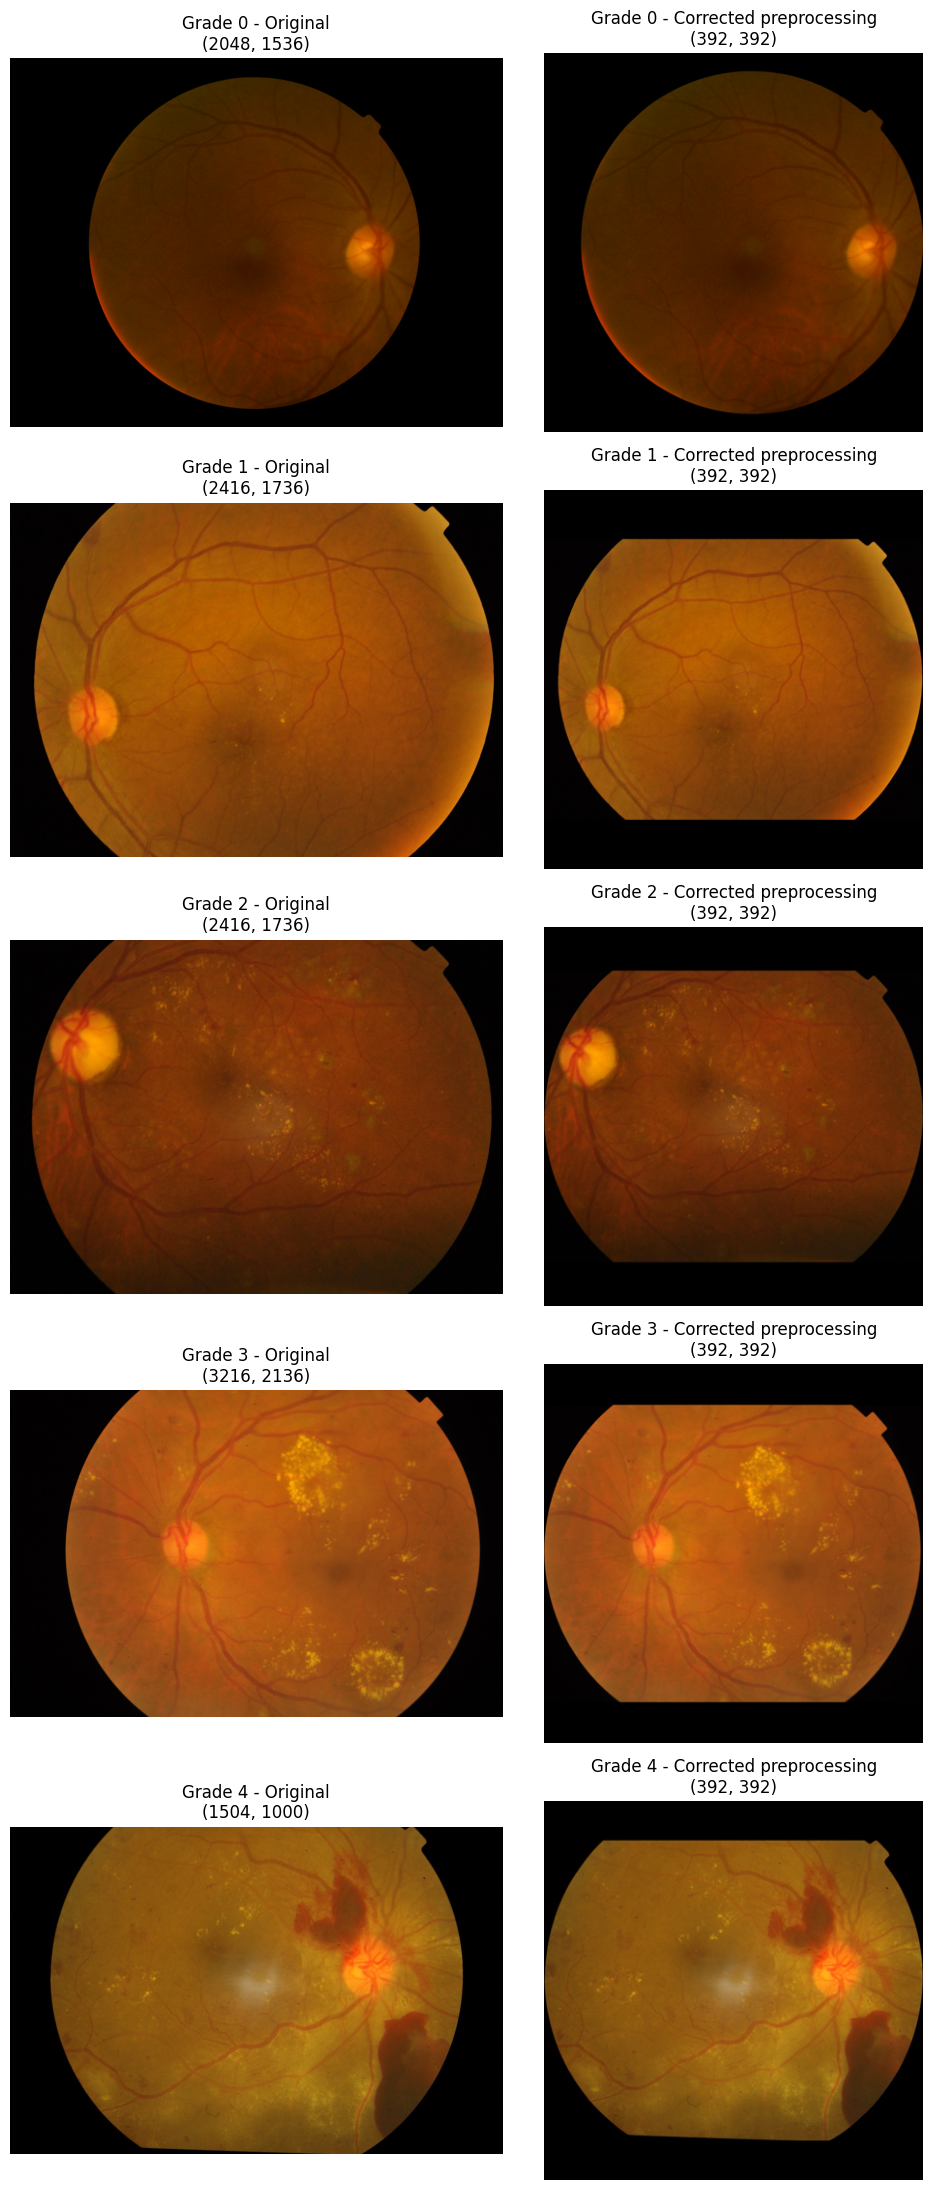


Preprocessing:
1. Remove obvious black outer border
2. Preserve original aspect ratio
3. Pad to square
4. Resize to 392 x 392

No image was saved or modified.


In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

# =========================================================
# PATHS
# =========================================================
IMAGE_DIR = Path("/content/APTOS/train_images")

AUDIT_PATH = Path(
    "/content/drive/MyDrive/thesis_DR/aptos_exact_duplicate_audit.csv"
)

TARGET_SIZE = 392

# =========================================================
# LOAD ONLY KEEP IMAGES
# =========================================================
audit = pd.read_csv(
    AUDIT_PATH,
    dtype={"image_id": str}
)

keep_df = audit[
    audit["action"] == "KEEP"
].copy()

print("KEEP images:", len(keep_df))

# =========================================================
# REMOVE ONLY OBVIOUS BLACK OUTER BORDER
# =========================================================
def remove_black_border(image, threshold=7):

    img = np.asarray(image)

    gray = (
        0.299 * img[:, :, 0] +
        0.587 * img[:, :, 1] +
        0.114 * img[:, :, 2]
    )

    mask = gray > threshold

    if not mask.any():
        return image

    rows = np.where(mask.any(axis=1))[0]
    cols = np.where(mask.any(axis=0))[0]

    top = rows[0]
    bottom = rows[-1]
    left = cols[0]
    right = cols[-1]

    cropped = img[
        top:bottom + 1,
        left:right + 1
    ]

    return Image.fromarray(cropped)

# =========================================================
# PAD TO SQUARE WITHOUT DISTORTING IMAGE
# =========================================================
def pad_to_square(image):

    width, height = image.size

    side = max(width, height)

    square = Image.new(
        "RGB",
        (side, side),
        (0, 0, 0)
    )

    left = (side - width) // 2
    top = (side - height) // 2

    square.paste(
        image,
        (left, top)
    )

    return square

# =========================================================
# FINAL PREPROCESSING PREVIEW
# =========================================================
def preprocess_preview(image_path):

    original = Image.open(
        image_path
    ).convert("RGB")

    cropped = remove_black_border(original)

    squared = pad_to_square(cropped)

    resized = squared.resize(
        (TARGET_SIZE, TARGET_SIZE),
        Image.Resampling.BICUBIC
    )

    return original, resized

# =========================================================
# ONE KEEP IMAGE FROM EACH GRADE
# =========================================================
samples = (
    keep_df
    .groupby("original_grade", group_keys=False)
    .sample(n=1, random_state=42)
    .sort_values("original_grade")
)

# =========================================================
# ORIGINAL VS CORRECTED PREPROCESSING
# =========================================================
fig, axes = plt.subplots(
    5, 2,
    figsize=(10, 22)
)

for row_no, (_, row) in enumerate(samples.iterrows()):

    image_path = (
        IMAGE_DIR /
        f"{row['image_id']}.png"
    )

    original, processed = preprocess_preview(
        image_path
    )

    axes[row_no, 0].imshow(original)
    axes[row_no, 0].set_title(
        f"Grade {row['original_grade']} - Original\n"
        f"{original.size}"
    )
    axes[row_no, 0].axis("off")

    axes[row_no, 1].imshow(processed)
    axes[row_no, 1].set_title(
        f"Grade {row['original_grade']} - Corrected preprocessing\n"
        f"{processed.size}"
    )
    axes[row_no, 1].axis("off")

plt.tight_layout()
plt.show()

print("\nPreprocessing:")
print("1. Remove obvious black outer border")
print("2. Preserve original aspect ratio")
print("3. Pad to square")
print("4. Resize to 392 x 392")
print("\nNo image was saved or modified.")

**Spliting**

In [ ]:
import pandas as pd
from pathlib import Path
from sklearn.model_selection import train_test_split

# =========================================================
# PATHS
# =========================================================
AUDIT_PATH = Path(
    "/content/drive/MyDrive/thesis_DR/aptos_exact_duplicate_audit.csv"
)

SAVE_PATH = Path(
    "/content/drive/MyDrive/thesis_DR/aptos_split_manifest.csv"
)

# Fixed reproducible seeds
SEEDS = [42, 43, 44, 45, 46]

# =========================================================
# LOAD ONLY KEEP IMAGES
# =========================================================
audit = pd.read_csv(
    AUDIT_PATH,
    dtype={"image_id": str}
)

data = audit[
    audit["action"] == "KEEP"
][
    ["image_id", "original_grade", "binary_label"]
].copy()

print("Images entering split:", len(data))

# =========================================================
# CREATE 5 STRATIFIED SPLITS
# =========================================================
all_splits = []

for seed in SEEDS:

    # 60% development / 40% remaining
    development, remaining = train_test_split(
        data,
        test_size=0.40,
        random_state=seed,
        stratify=data["original_grade"]
    )

    # Remaining 40%:
    # 10% total probability calibration
    # = 25% of remaining
    prob_calibration, remaining_30 = train_test_split(
        remaining,
        test_size=0.75,
        random_state=seed,
        stratify=remaining["original_grade"]
    )

    # Remaining 30%:
    # 15% risk calibration
    # 15% internal test
    risk_calibration, internal_test = train_test_split(
        remaining_30,
        test_size=0.50,
        random_state=seed,
        stratify=remaining_30["original_grade"]
    )

    development = development.copy()
    prob_calibration = prob_calibration.copy()
    risk_calibration = risk_calibration.copy()
    internal_test = internal_test.copy()

    development["split"] = "development"
    prob_calibration["split"] = "prob_calibration"
    risk_calibration["split"] = "risk_calibration"
    internal_test["split"] = "internal_test"

    split_df = pd.concat([
        development,
        prob_calibration,
        risk_calibration,
        internal_test
    ])

    split_df["seed"] = seed

    all_splits.append(split_df)

# =========================================================
# COMBINE AND SAVE ONE MANIFEST
# =========================================================
manifest = pd.concat(
    all_splits,
    ignore_index=True
)

manifest = manifest[
    [
        "seed",
        "image_id",
        "original_grade",
        "binary_label",
        "split"
    ]
]

manifest.to_csv(
    SAVE_PATH,
    index=False
)

# =========================================================
# VERIFY
# =========================================================
print("\n========== APTOS SOURCE SPLIT SUMMARY ==========")

print("\nMethod:")
print("Repeated stratified splitting using original DR grades 0-4")

print("\nSeeds:", SEEDS)

for seed in SEEDS:

    s = manifest[
        manifest["seed"] == seed
    ]

    print(f"\n---------- SEED {seed} ----------")

    counts = s["split"].value_counts()

    for split_name in [
        "development",
        "prob_calibration",
        "risk_calibration",
        "internal_test"
    ]:
        n = counts[split_name]
        pct = n / len(s) * 100

        print(
            f"{split_name}: {n} ({pct:.2f}%)"
        )

    print("Total:", len(s))

    # Check every image appears exactly once
    unique_images = s["image_id"].nunique()

    print(
        "Unique images:",
        unique_images
    )

    if unique_images == len(data):
        print("Split integrity: PASS")
    else:
        print("Split integrity: FAIL")

print("\nSaved permanently:")
print(SAVE_PATH)

print("\n========== SPLITTING COMPLETE ==========")

We intentionally used minimal preprocessing to preserve the native retinal appearance and avoid introducing an additional image-enhancement confounder. Because our objective was to evaluate the pretrained retinal foundation model and its calibration/selective-risk behavior under distribution shift, aggressive contrast or color transformations were not applied

#**Model RETFound-Green embedding extraction.**

In [10]:
# ============================================================
# APTOS -> RETFound-Green Frozen Embeddings
# ============================================================

!pip -q install timm==0.9.12

import os
import urllib.request
import numpy as np
import pandas as pd
import torch
import timm

from pathlib import Path
from PIL import Image
from tqdm.auto import tqdm
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import v2 as T


# ============================================================
# 1. PATHS
# ============================================================

IMAGE_DIR = Path("/content/APTOS/train_images")

AUDIT_PATH = Path(
    "/content/drive/MyDrive/thesis_DR/aptos_exact_duplicate_audit.csv"
)

SAVE_PATH = Path(
    "/content/drive/MyDrive/thesis_DR/aptos_retfound_green_embeddings.npz"
)

CHECKPOINT_PATH = Path(
    "/content/retfoundgreen_statedict.pth"
)


# ============================================================
# 2. LOAD ONLY THE 3504 KEEP IMAGES
# ============================================================

audit = pd.read_csv(
    AUDIT_PATH,
    dtype={"image_id": str}
)

keep_df = (
    audit[audit["action"] == "KEEP"]
    [["image_id", "original_grade", "binary_label"]]
    .sort_values("image_id")
    .reset_index(drop=True)
)

print("APTOS KEEP images:", len(keep_df))


# ============================================================
# 3. LOCKED PREPROCESSING
# ============================================================

def remove_black_border(image, threshold=7):

    img = np.asarray(image)

    gray = (
        0.299 * img[:, :, 0] +
        0.587 * img[:, :, 1] +
        0.114 * img[:, :, 2]
    )

    mask = gray > threshold

    if not mask.any():
        return image

    rows = np.where(mask.any(axis=1))[0]
    cols = np.where(mask.any(axis=0))[0]

    cropped = img[
        rows[0]:rows[-1] + 1,
        cols[0]:cols[-1] + 1
    ]

    return Image.fromarray(cropped)


def pad_to_square(image):

    width, height = image.size
    side = max(width, height)

    square = Image.new(
        "RGB",
        (side, side),
        (0, 0, 0)
    )

    left = (side - width) // 2
    top = (side - height) // 2

    square.paste(image, (left, top))

    return square


# Official RETFound-Green resolution + normalization
transform = T.Compose([
    T.Resize((392, 392), antialias=True),
    T.ToImage(),
    T.ToDtype(torch.float32, scale=True),
    T.Normalize(
        mean=(0.5, 0.5, 0.5),
        std=(0.5, 0.5, 0.5)
    )
])


# ============================================================
# 4. DATASET
# ============================================================

class APTOSDataset(Dataset):

    def __init__(self, dataframe, image_dir):
        self.df = dataframe
        self.image_dir = image_dir

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        image_id = row["image_id"]
        image_path = self.image_dir / f"{image_id}.png"

        image = Image.open(image_path).convert("RGB")

        # Our locked preprocessing
        image = remove_black_border(image)
        image = pad_to_square(image)

        # RETFound-Green resize + normalization
        image = transform(image)

        return (
            image,
            image_id,
            int(row["original_grade"]),
            int(row["binary_label"])
        )


# ============================================================
# 5. DOWNLOAD OFFICIAL RETFOUND-GREEN WEIGHTS
# ============================================================

if not CHECKPOINT_PATH.exists():

    print("\nDownloading official RETFound-Green checkpoint...")

    url = (
        "https://github.com/justinengelmann/"
        "RETFound_Green/releases/download/v0.1/"
        "retfoundgreen_statedict.pth"
    )

    urllib.request.urlretrieve(
        url,
        CHECKPOINT_PATH
    )

else:
    print("\nRETFound-Green checkpoint already exists.")


# ============================================================
# 6. LOAD OFFICIAL RETFOUND-GREEN
# ============================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

model = timm.create_model(
    "vit_small_patch14_reg4_dinov2",
    img_size=(392, 392),
    num_classes=0,
    checkpoint_path=str(CHECKPOINT_PATH)
)

model.global_pool = "avg"

# Freeze encoder
for parameter in model.parameters():
    parameter.requires_grad = False

model = model.to(device)
model.eval()

print("RETFound-Green loaded.")
print("Encoder frozen:", not any(
    p.requires_grad for p in model.parameters()
))


# ============================================================
# 7. DATALOADER
# ============================================================

dataset = APTOSDataset(
    keep_df,
    IMAGE_DIR
)

loader = DataLoader(
    dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)


# ============================================================
# 8. EXTRACT ALL EMBEDDINGS
# ============================================================

all_embeddings = []
all_image_ids = []
all_grades = []
all_binary_labels = []

with torch.inference_mode():

    for images, image_ids, grades, labels in tqdm(
        loader,
        desc="Extracting RETFound-Green embeddings"
    ):

        images = images.to(
            device,
            non_blocking=True
        )

        features = model(images)

        all_embeddings.append(
            features.cpu().numpy()
        )

        all_image_ids.extend(image_ids)

        all_grades.extend(
            grades.numpy()
        )

        all_binary_labels.extend(
            labels.numpy()
        )


# ============================================================
# 9. COMBINE
# ============================================================

embeddings = np.concatenate(
    all_embeddings,
    axis=0
).astype(np.float32)

image_ids = np.asarray(all_image_ids)

grades = np.asarray(
    all_grades,
    dtype=np.int64
)

binary_labels = np.asarray(
    all_binary_labels,
    dtype=np.int64
)


# ============================================================
# 10. VERIFY BEFORE SAVING
# ============================================================

assert embeddings.shape[0] == 3504
assert len(image_ids) == 3504
assert len(np.unique(image_ids)) == 3504
assert not np.isnan(embeddings).any()
assert not np.isinf(embeddings).any()


# ============================================================
# 11. SAVE ONE PERMANENT FILE
# ============================================================

np.savez_compressed(
    SAVE_PATH,
    embeddings=embeddings,
    image_id=image_ids,
    original_grade=grades,
    binary_label=binary_labels
)


# ============================================================
# 12. FINAL REPORT
# ============================================================

print("\n========== RETFOUND-GREEN EMBEDDING EXTRACTION ==========")

print("\nModel:")
print("RETFound-Green")
print("Architecture: ViT-Small/14 + 4 register tokens")
print("Encoder status: FROZEN")

print("\nPreprocessing:")
print("1. Remove obvious black outer border")
print("2. Preserve aspect ratio")
print("3. Pad to square")
print("4. Resize to 392 x 392")
print("5. Normalize with mean=0.5 and std=0.5")

print("\nImages processed:", len(image_ids))
print("Embedding shape:", embeddings.shape)

print("NaN values:", np.isnan(embeddings).sum())
print("Infinite values:", np.isinf(embeddings).sum())

print("\nSaved permanently:")
print(SAVE_PATH)

print("\n========== COMPLETE ==========")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.6/60.6 kB 5.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 58.5 MB/s eta 0:00:00
APTOS KEEP images: 3504

Device: cuda
RETFound-Green loaded.
Encoder frozen: True


Extracting RETFound-Green embeddings:   0%|          | 0/110 [00:00<?, ?it/s]


========== RETFOUND-GREEN EMBEDDING EXTRACTION ==========

Model:
RETFound-Green
Architecture: ViT-Small/14 + 4 register tokens
Encoder status: FROZEN

Preprocessing:
1. Remove obvious black outer border
2. Preserve aspect ratio
3. Pad to square
4. Resize to 392 x 392
5. Normalize with mean=0.5 and std=0.5

Images processed: 3504
Embedding shape: (3504, 384)
NaN values: 0
Infinite values: 0

Saved permanently:
/content/drive/MyDrive/thesis_DR/aptos_retfound_green_embeddings.npz

========== COMPLETE ==========


In [12]:
from pathlib import Path

files_to_delete = [
    Path("/content/drive/MyDrive/thesis_DR/aptos_retfound_mlp_heads.pt"),
    Path("/content/drive/MyDrive/thesis_DR/aptos_retfound_raw_predictions.csv")
]

for f in files_to_delete:
    if f.exists():
        f.unlink()
        print("Deleted:", f.name)
    else:
        print("Already absent:", f.name)

Deleted: aptos_retfound_mlp_heads.pt
Deleted: aptos_retfound_raw_predictions.csv


In [13]:
# ============================================================
# FINAL RETFOUND-GREEN MLP TRAINING
#
# - Frozen RETFound-Green embeddings
# - Development split ONLY for HPO/training
# - 3-fold inner stratified CV
# - Small predefined HPO
# - Early stopping, max 25 epochs
# - Final retraining on full development set
# ============================================================

import random
import copy
import numpy as np
import pandas as pd
import torch

from pathlib import Path
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import StratifiedKFold


# ============================================================
# 1. PATHS
# ============================================================

PROJECT_DIR = Path("/content/drive/MyDrive/thesis_DR")

EMBEDDING_PATH = (
    PROJECT_DIR / "aptos_retfound_green_embeddings.npz"
)

SPLIT_PATH = (
    PROJECT_DIR / "aptos_split_manifest.csv"
)

MODEL_SAVE_PATH = (
    PROJECT_DIR / "aptos_retfound_mlp_heads.pt"
)

PRED_SAVE_PATH = (
    PROJECT_DIR / "aptos_retfound_raw_predictions.csv"
)


# ============================================================
# 2. LOCKED SETTINGS
# ============================================================

SEEDS = [42, 43, 44, 45, 46]

INPUT_DIM = 384
HIDDEN_DIM = 512
DROPOUT = 0.10

BATCH_SIZE = 64

MAX_EPOCHS = 25
EARLY_STOP_PATIENCE = 4
MIN_DELTA = 1e-5

INNER_FOLDS = 3

# Small prespecified HPO only
HPO_CONFIGS = [
    {
        "name": "A",
        "learning_rate": 3e-4,
        "weight_decay": 0.0
    },
    {
        "name": "B",
        "learning_rate": 3e-4,
        "weight_decay": 1e-4
    },
    {
        "name": "C",
        "learning_rate": 1e-3,
        "weight_decay": 0.0
    },
    {
        "name": "D",
        "learning_rate": 1e-3,
        "weight_decay": 1e-4
    }
]


# ============================================================
# 3. REPRODUCIBILITY
# ============================================================

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


# ============================================================
# 4. MODEL
# ============================================================

class MLPHead(nn.Module):

    def __init__(
        self,
        input_dim=384,
        hidden_dim=512,
        dropout=0.10
    ):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, 1)
        )

    def forward(self, x):
        return self.network(x).squeeze(1)


# ============================================================
# 5. DEVICE
# ============================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)


# ============================================================
# 6. LOAD EMBEDDINGS
# ============================================================

saved_embeddings = np.load(
    EMBEDDING_PATH,
    allow_pickle=False
)

embeddings = saved_embeddings[
    "embeddings"
].astype(np.float32)

embedding_ids = saved_embeddings[
    "image_id"
].astype(str)

embedding_grades = saved_embeddings[
    "original_grade"
].astype(int)

embedding_labels = saved_embeddings[
    "binary_label"
].astype(int)


# ============================================================
# 7. VERIFY EMBEDDINGS
# ============================================================

assert embeddings.shape == (3504, 384)
assert len(np.unique(embedding_ids)) == 3504
assert np.isfinite(embeddings).all()

print("\n========== INPUT CHECK ==========")
print("Embedding shape:", embeddings.shape)
print("Unique image IDs:", len(np.unique(embedding_ids)))


# ============================================================
# 8. LOAD SPLIT MANIFEST
# ============================================================

manifest = pd.read_csv(
    SPLIT_PATH,
    dtype={"image_id": str}
)

assert sorted(
    manifest["seed"].unique().tolist()
) == SEEDS

print("Manifest rows:", len(manifest))
print("Seeds:", SEEDS)


# ============================================================
# 9. EMBEDDING LOOKUP
# ============================================================

embedding_meta = pd.DataFrame({
    "image_id": embedding_ids,
    "embedding_index": np.arange(len(embedding_ids)),
    "embedding_grade": embedding_grades,
    "embedding_label": embedding_labels
})


# ============================================================
# 10. TRAIN WITH INNER VALIDATION + EARLY STOPPING
# ============================================================

def train_with_early_stopping(
    X_train,
    y_train,
    X_val,
    y_val,
    learning_rate,
    weight_decay,
    run_seed
):

    set_seed(run_seed)

    model = MLPHead(
        INPUT_DIM,
        HIDDEN_DIM,
        DROPOUT
    ).to(device)

    criterion = nn.BCEWithLogitsLoss()

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=learning_rate,
        weight_decay=weight_decay
    )

    train_dataset = TensorDataset(
        torch.tensor(
            X_train,
            dtype=torch.float32
        ),
        torch.tensor(
            y_train,
            dtype=torch.float32
        )
    )

    generator = torch.Generator()
    generator.manual_seed(run_seed)

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=generator
    )

    X_val_tensor = torch.tensor(
        X_val,
        dtype=torch.float32,
        device=device
    )

    y_val_tensor = torch.tensor(
        y_val,
        dtype=torch.float32,
        device=device
    )

    best_val_loss = float("inf")
    best_epoch = 1
    best_state = None

    patience_counter = 0

    train_history = []
    val_history = []

    for epoch in range(1, MAX_EPOCHS + 1):

        # ---------------------------
        # TRAIN
        # ---------------------------

        model.train()

        running_loss = 0.0
        n_seen = 0

        for batch_x, batch_y in train_loader:

            batch_x = batch_x.to(device)
            batch_y = batch_y.to(device)

            optimizer.zero_grad(set_to_none=True)

            logits = model(batch_x)

            loss = criterion(
                logits,
                batch_y
            )

            loss.backward()
            optimizer.step()

            batch_n = batch_x.size(0)

            running_loss += (
                loss.item() * batch_n
            )

            n_seen += batch_n

        train_loss = running_loss / n_seen

        # ---------------------------
        # VALIDATION
        # ---------------------------

        model.eval()

        with torch.inference_mode():

            val_logits = model(
                X_val_tensor
            )

            val_loss = criterion(
                val_logits,
                y_val_tensor
            ).item()

        train_history.append(
            float(train_loss)
        )

        val_history.append(
            float(val_loss)
        )

        # ---------------------------
        # EARLY STOPPING
        # ---------------------------

        if val_loss < (
            best_val_loss - MIN_DELTA
        ):

            best_val_loss = val_loss
            best_epoch = epoch

            best_state = copy.deepcopy(
                model.state_dict()
            )

            patience_counter = 0

        else:

            patience_counter += 1

        if patience_counter >= EARLY_STOP_PATIENCE:
            break

    # Restore best fold model
    model.load_state_dict(
        best_state
    )

    result = {
        "best_val_loss": float(best_val_loss),
        "best_epoch": int(best_epoch),
        "epochs_run": int(len(train_history)),
        "train_loss_history": train_history,
        "val_loss_history": val_history
    }

    del model
    del X_val_tensor
    del y_val_tensor

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return result


# ============================================================
# 11. FINAL TRAINING ON FULL DEVELOPMENT SET
# ============================================================

def train_final_head(
    X,
    y,
    learning_rate,
    weight_decay,
    epochs,
    run_seed
):

    set_seed(run_seed)

    model = MLPHead(
        INPUT_DIM,
        HIDDEN_DIM,
        DROPOUT
    ).to(device)

    criterion = nn.BCEWithLogitsLoss()

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=learning_rate,
        weight_decay=weight_decay
    )

    dataset = TensorDataset(
        torch.tensor(
            X,
            dtype=torch.float32
        ),
        torch.tensor(
            y,
            dtype=torch.float32
        )
    )

    generator = torch.Generator()
    generator.manual_seed(run_seed)

    loader = DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=generator
    )

    loss_history = []

    for epoch in range(epochs):

        model.train()

        running_loss = 0.0
        n_seen = 0

        for batch_x, batch_y in loader:

            batch_x = batch_x.to(device)
            batch_y = batch_y.to(device)

            optimizer.zero_grad(
                set_to_none=True
            )

            logits = model(batch_x)

            loss = criterion(
                logits,
                batch_y
            )

            loss.backward()
            optimizer.step()

            batch_n = batch_x.size(0)

            running_loss += (
                loss.item() * batch_n
            )

            n_seen += batch_n

        epoch_loss = (
            running_loss / n_seen
        )

        loss_history.append(
            float(epoch_loss)
        )

    return model, loss_history


# ============================================================
# 12. STORAGE
# ============================================================

saved_heads = {}
prediction_tables = []


# ============================================================
# 13. RUN EACH OUTER SEED
# ============================================================

print(
    "\n========== FINAL RETFOUND-GREEN MLP TRAINING =========="
)

print("\nBackbone: RETFound-Green")
print("Encoder: FROZEN")

print("\nArchitecture:")
print(
    "384 -> 512 -> ReLU -> "
    "Dropout(0.1) -> 1 logit"
)

print("\nHPO:")
print("3-fold inner stratified CV")
print("Stratification: original grades 0-4")
print("Selection metric: validation BCE loss")

print("\nEarly stopping:")
print("Maximum epochs:", MAX_EPOCHS)
print(
    "Patience:",
    EARLY_STOP_PATIENCE
)

print("\nIMPORTANT:")
print("HPO uses DEVELOPMENT data only.")
print(
    "Probability-calibration data: NOT USED"
)
print(
    "Risk-calibration data: NOT USED"
)
print(
    "Internal-test data: NOT USED"
)


for seed in SEEDS:

    print(
        f"\n\n========== SEED {seed} =========="
    )

    # --------------------------------------------------------
    # Build manifest for this seed
    # --------------------------------------------------------

    seed_df = (
        manifest[
            manifest["seed"] == seed
        ]
        .copy()
        .merge(
            embedding_meta,
            on="image_id",
            how="left",
            validate="one_to_one"
        )
    )

    assert (
        seed_df["embedding_index"]
        .isna()
        .sum()
        == 0
    )

    # Verify labels
    assert (
        seed_df[
            "original_grade"
        ].astype(int).values
        ==
        seed_df[
            "embedding_grade"
        ].astype(int).values
    ).all()

    assert (
        seed_df[
            "binary_label"
        ].astype(int).values
        ==
        seed_df[
            "embedding_label"
        ].astype(int).values
    ).all()

    # --------------------------------------------------------
    # DEVELOPMENT ONLY
    # --------------------------------------------------------

    dev_df = (
        seed_df[
            seed_df["split"]
            == "development"
        ]
        .copy()
        .reset_index(drop=True)
    )

    dev_embedding_indices = (
        dev_df[
            "embedding_index"
        ]
        .astype(int)
        .values
    )

    X_dev = embeddings[
        dev_embedding_indices
    ]

    y_dev = (
        dev_df[
            "binary_label"
        ]
        .astype(int)
        .values
    )

    grades_dev = (
        dev_df[
            "original_grade"
        ]
        .astype(int)
        .values
    )

    print(
        "Development images:",
        len(dev_df)
    )

    print(
        "Non-referable:",
        int((y_dev == 0).sum())
    )

    print(
        "Referable:",
        int((y_dev == 1).sum())
    )

    # --------------------------------------------------------
    # FIXED 3-FOLD INNER CV
    # --------------------------------------------------------

    skf = StratifiedKFold(
        n_splits=INNER_FOLDS,
        shuffle=True,
        random_state=seed
    )

    hpo_results = []

    # --------------------------------------------------------
    # TEST EACH CONFIGURATION
    # --------------------------------------------------------

    for config_index, config in enumerate(
        HPO_CONFIGS
    ):

        fold_results = []

        # Same folds for every config
        for fold_number, (
            train_idx,
            val_idx
        ) in enumerate(
            skf.split(
                X_dev,
                grades_dev
            ),
            start=1
        ):

            # Same initialization seed across
            # configurations for a given fold
            fold_seed = (
                seed * 100
                + fold_number
            )

            result = train_with_early_stopping(
                X_train=X_dev[train_idx],
                y_train=y_dev[train_idx],

                X_val=X_dev[val_idx],
                y_val=y_dev[val_idx],

                learning_rate=config[
                    "learning_rate"
                ],

                weight_decay=config[
                    "weight_decay"
                ],

                run_seed=fold_seed
            )

            fold_results.append(
                result
            )

        fold_losses = [
            result["best_val_loss"]
            for result in fold_results
        ]

        fold_epochs = [
            result["best_epoch"]
            for result in fold_results
        ]

        mean_val_loss = float(
            np.mean(fold_losses)
        )

        std_val_loss = float(
            np.std(
                fold_losses,
                ddof=1
            )
        )

        config_result = {
            "name": config["name"],
            "learning_rate": config[
                "learning_rate"
            ],
            "weight_decay": config[
                "weight_decay"
            ],
            "mean_val_loss": mean_val_loss,
            "std_val_loss": std_val_loss,
            "fold_best_epochs": fold_epochs,
            "fold_results": fold_results
        }

        hpo_results.append(
            config_result
        )

        print(
            f"\nConfig {config['name']}:"
        )

        print(
            "  Learning rate:",
            config["learning_rate"]
        )

        print(
            "  Weight decay:",
            config["weight_decay"]
        )

        print(
            "  Fold best epochs:",
            fold_epochs
        )

        print(
            "  Mean validation BCE:",
            f"{mean_val_loss:.6f}"
        )

        print(
            "  Std validation BCE:",
            f"{std_val_loss:.6f}"
        )

    # --------------------------------------------------------
    # SELECT BEST CONFIG
    # --------------------------------------------------------

    best_config = min(
        hpo_results,
        key=lambda x: x[
            "mean_val_loss"
        ]
    )

    selected_epochs = int(
        np.median(
            best_config[
                "fold_best_epochs"
            ]
        )
    )

    selected_epochs = max(
        1,
        min(
            selected_epochs,
            MAX_EPOCHS
        )
    )

    print(
        "\n---------- SELECTED ----------"
    )

    print(
        "Configuration:",
        best_config["name"]
    )

    print(
        "Learning rate:",
        best_config[
            "learning_rate"
        ]
    )

    print(
        "Weight decay:",
        best_config[
            "weight_decay"
        ]
    )

    print(
        "Mean CV validation BCE:",
        f"{best_config['mean_val_loss']:.6f}"
    )

    print(
        "Fold best epochs:",
        best_config[
            "fold_best_epochs"
        ]
    )

    print(
        "Final training epochs:",
        selected_epochs
    )

    # --------------------------------------------------------
    # RETRAIN USING ALL 2102 DEVELOPMENT IMAGES
    # --------------------------------------------------------

    final_seed = (
        seed * 1000 + 999
    )

    final_model, final_loss_history = (
        train_final_head(
            X=X_dev,
            y=y_dev,

            learning_rate=best_config[
                "learning_rate"
            ],

            weight_decay=best_config[
                "weight_decay"
            ],

            epochs=selected_epochs,

            run_seed=final_seed
        )
    )

    print(
        "Final development training loss:",
        f"{final_loss_history[-1]:.6f}"
    )

    # --------------------------------------------------------
    # GENERATE RAW PREDICTIONS FOR ALL 3504 IMAGES
    # --------------------------------------------------------

    all_indices = (
        seed_df[
            "embedding_index"
        ]
        .astype(int)
        .values
    )

    X_all = torch.tensor(
        embeddings[
            all_indices
        ],
        dtype=torch.float32,
        device=device
    )

    final_model.eval()

    with torch.inference_mode():

        raw_logits = final_model(
            X_all
        )

        raw_probabilities = (
            torch.sigmoid(
                raw_logits
            )
        )

    raw_logits = (
        raw_logits
        .cpu()
        .numpy()
        .astype(np.float32)
    )

    raw_probabilities = (
        raw_probabilities
        .cpu()
        .numpy()
        .astype(np.float32)
    )

    # --------------------------------------------------------
    # SAVE PREDICTION TABLE IN MEMORY
    # --------------------------------------------------------

    pred_df = seed_df[
        [
            "seed",
            "image_id",
            "split",
            "original_grade",
            "binary_label"
        ]
    ].copy()

    pred_df[
        "raw_logit"
    ] = raw_logits

    pred_df[
        "raw_probability"
    ] = raw_probabilities

    prediction_tables.append(
        pred_df
    )

    # --------------------------------------------------------
    # SAVE MODEL INFORMATION IN MEMORY
    # --------------------------------------------------------

    cpu_state_dict = {
        name: tensor
        .detach()
        .cpu()
        for name, tensor
        in final_model.state_dict().items()
    }

    saved_heads[seed] = {

        "state_dict":
            cpu_state_dict,

        "selected_config":
            best_config["name"],

        "selected_learning_rate":
            float(
                best_config[
                    "learning_rate"
                ]
            ),

        "selected_weight_decay":
            float(
                best_config[
                    "weight_decay"
                ]
            ),

        "selected_epochs":
            int(selected_epochs),

        "development_images":
            int(len(dev_df)),

        "development_non_referable":
            int((y_dev == 0).sum()),

        "development_referable":
            int((y_dev == 1).sum()),

        "final_training_loss":
            float(
                final_loss_history[-1]
            ),

        "final_loss_history":
            final_loss_history,

        "hpo_results":
            hpo_results
    }

    del final_model
    del X_all

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# ============================================================
# 14. COMBINE ALL RAW PREDICTIONS
# ============================================================

predictions = pd.concat(
    prediction_tables,
    ignore_index=True
)

expected_rows = (
    3504 * len(SEEDS)
)

assert len(predictions) == expected_rows

assert (
    predictions[
        "raw_logit"
    ]
    .isna()
    .sum()
    == 0
)

assert (
    predictions[
        "raw_probability"
    ]
    .isna()
    .sum()
    == 0
)

assert np.isfinite(
    predictions[
        "raw_logit"
    ].values
).all()


# ============================================================
# 15. SAVE FINAL MODEL BUNDLE
# ============================================================

model_bundle = {

    "backbone":
        "RETFound-Green",

    "encoder_status":
        "frozen",

    "embedding_dim":
        384,

    "head_architecture": {
        "input_dim": 384,
        "hidden_dim": 512,
        "activation": "ReLU",
        "dropout": 0.10,
        "output_dim": 1
    },

    "training_protocol": {

        "loss":
            "BCEWithLogitsLoss",

        "optimizer":
            "AdamW",

        "batch_size":
            BATCH_SIZE,

        "max_epochs":
            MAX_EPOCHS,

        "early_stopping_patience":
            EARLY_STOP_PATIENCE,

        "inner_cv_folds":
            INNER_FOLDS,

        "inner_cv_stratification":
            "original_grade_0_to_4",

        "hpo_selection_metric":
            "mean_inner_validation_BCE",

        "final_epoch_rule":
            "median_best_epoch_of_selected_configuration",

        "class_weighting":
            None
    },

    "hpo_configs":
        HPO_CONFIGS,

    "seeds":
        SEEDS,

    "heads":
        saved_heads
}

torch.save(
    model_bundle,
    MODEL_SAVE_PATH
)


# ============================================================
# 16. SAVE RAW PREDICTIONS
# ============================================================

predictions.to_csv(
    PRED_SAVE_PATH,
    index=False
)


# ============================================================
# 17. FINAL REPORT
# ============================================================

print(
    "\n\n========== FINAL TRAINING SUMMARY =========="
)

print(
    "\nHeads trained:",
    len(saved_heads),
    "/ 5"
)

for seed in SEEDS:

    info = saved_heads[seed]

    print(
        f"\nSeed {seed}:"
    )

    print(
        "  Selected config:",
        info["selected_config"]
    )

    print(
        "  Learning rate:",
        info[
            "selected_learning_rate"
        ]
    )

    print(
        "  Weight decay:",
        info[
            "selected_weight_decay"
        ]
    )

    print(
        "  Final epochs:",
        info[
            "selected_epochs"
        ]
    )

print(
    "\nRaw prediction rows:",
    len(predictions)
)

print(
    "Expected rows:",
    expected_rows
)

print(
    "NaN logits:",
    predictions[
        "raw_logit"
    ]
    .isna()
    .sum()
)

print(
    "Infinite logits:",
    np.isinf(
        predictions[
            "raw_logit"
        ].values
    ).sum()
)

print("\nIMPORTANT:")
print(
    "Probability-calibration data was NOT used for HPO/training."
)

print(
    "Risk-calibration data was NOT used for HPO/training."
)

print(
    "Internal-test data was NOT used for HPO/training."
)

print(
    "Raw probabilities are still UNCALIBRATED."
)

print(
    "No selective threshold has been selected."
)

print(
    "No risk-control method has been applied."
)

print("\nSaved final model bundle:")
print(MODEL_SAVE_PATH)

print("\nSaved raw predictions:")
print(PRED_SAVE_PATH)

print(
    "\n========== COMPLETE =========="
)

Device: cuda

========== INPUT CHECK ==========
Embedding shape: (3504, 384)
Unique image IDs: 3504


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Manifest rows: 17520
Seeds: [42, 43, 44, 45, 46]

========== FINAL RETFOUND-GREEN MLP TRAINING ==========

Backbone: RETFound-Green
Encoder: FROZEN

Architecture:
384 -> 512 -> ReLU -> Dropout(0.1) -> 1 logit

HPO:
3-fold inner stratified CV
Stratification: original grades 0-4
Selection metric: validation BCE loss

Early stopping:
Maximum epochs: 25
Patience: 4

IMPORTANT:
HPO uses DEVELOPMENT data only.
Probability-calibration data: NOT USED
Risk-calibration data: NOT USED
Internal-test data: NOT USED


========== SEED 42 ==========
Development images: 2102
Non-referable: 1280
Referable: 822

Config A:
  Learning rate: 0.0003
  Weight decay: 0.0
  Fold best epochs: [23, 18, 24]
  Mean validation BCE: 0.166316
  Std validation BCE: 0.004106

Config B:
  Learning rate: 0.0003
  Weight decay: 0.0001
  Fold best epochs: [23, 18, 24]
  Mean validation BCE: 0.166311
  Std validation BCE: 0.004089

Config C:
  Learning rate: 0.001
  Weight decay: 0.0
  Fold best epochs: [21, 9, 24]
  Mean va

#**Probability Calibration**

In [14]:
# ============================================================
# RETFOUND-GREEN PROBABILITY CALIBRATION
# Temperature Scaling
#
# Uses ONLY:
#   prob_calibration split
#
# Does NOT use:
#   development
#   risk_calibration
#   internal_test
#
# Saves ONLY:
#   aptos_retfound_temperature_scaling.json
# ============================================================

import json
import numpy as np
import pandas as pd

from pathlib import Path
from scipy.optimize import minimize_scalar
from scipy.special import expit


# ============================================================
# 1. PATHS
# ============================================================

PROJECT_DIR = Path(
    "/content/drive/MyDrive/thesis_DR"
)

PRED_PATH = (
    PROJECT_DIR /
    "aptos_retfound_raw_predictions.csv"
)

SAVE_PATH = (
    PROJECT_DIR /
    "aptos_retfound_temperature_scaling.json"
)


# ============================================================
# 2. SETTINGS
# ============================================================

SEEDS = [42, 43, 44, 45, 46]

ECE_BINS = 10


# ============================================================
# 3. LOAD RAW PREDICTIONS
# ============================================================

pred = pd.read_csv(
    PRED_PATH,
    dtype={"image_id": str}
)

print("========== INPUT CHECK ==========")

print("Prediction rows:", len(pred))
print(
    "Seeds:",
    sorted(pred["seed"].unique().tolist())
)

assert len(pred) == 3504 * 5

assert sorted(
    pred["seed"].unique().tolist()
) == SEEDS

assert pred["raw_logit"].isna().sum() == 0

assert np.isfinite(
    pred["raw_logit"].values
).all()


# ============================================================
# 4. METRIC FUNCTIONS
# ============================================================

def binary_nll_from_logits(logits, labels):
    """
    Numerically stable binary negative log-likelihood.
    """

    logits = np.asarray(
        logits,
        dtype=np.float64
    )

    labels = np.asarray(
        labels,
        dtype=np.float64
    )

    losses = (
        np.maximum(logits, 0)
        - logits * labels
        + np.log1p(
            np.exp(
                -np.abs(logits)
            )
        )
    )

    return float(
        np.mean(losses)
    )


def brier_score(probabilities, labels):

    probabilities = np.asarray(
        probabilities,
        dtype=np.float64
    )

    labels = np.asarray(
        labels,
        dtype=np.float64
    )

    return float(
        np.mean(
            (probabilities - labels) ** 2
        )
    )


def expected_calibration_error(
    probabilities,
    labels,
    n_bins=10
):

    probabilities = np.asarray(
        probabilities,
        dtype=np.float64
    )

    labels = np.asarray(
        labels,
        dtype=np.float64
    )

    edges = np.linspace(
        0.0,
        1.0,
        n_bins + 1
    )

    ece = 0.0
    n = len(labels)

    for i in range(n_bins):

        lower = edges[i]
        upper = edges[i + 1]

        if i == n_bins - 1:

            mask = (
                (probabilities >= lower)
                & (probabilities <= upper)
            )

        else:

            mask = (
                (probabilities >= lower)
                & (probabilities < upper)
            )

        count = int(mask.sum())

        if count == 0:
            continue

        confidence = float(
            probabilities[mask].mean()
        )

        accuracy = float(
            labels[mask].mean()
        )

        ece += (
            count / n
        ) * abs(
            accuracy - confidence
        )

    return float(ece)


# ============================================================
# 5. FIT ONE TEMPERATURE
# ============================================================

def fit_temperature(
    logits,
    labels
):

    logits = np.asarray(
        logits,
        dtype=np.float64
    )

    labels = np.asarray(
        labels,
        dtype=np.float64
    )

    # Optimize log(T), ensuring T > 0
    def objective(log_temperature):

        temperature = np.exp(
            log_temperature
        )

        calibrated_logits = (
            logits / temperature
        )

        return binary_nll_from_logits(
            calibrated_logits,
            labels
        )

    # Wide safe range:
    # T approximately 0.007 to 148
    result = minimize_scalar(
        objective,
        bounds=(-5.0, 5.0),
        method="bounded",
        options={
            "xatol": 1e-8
        }
    )

    temperature = float(
        np.exp(result.x)
    )

    # T = 1 means no calibration.
    # Never accept a solution worse than T=1
    original_nll = (
        binary_nll_from_logits(
            logits,
            labels
        )
    )

    optimized_nll = (
        binary_nll_from_logits(
            logits / temperature,
            labels
        )
    )

    if optimized_nll > original_nll:
        temperature = 1.0

    return temperature


# ============================================================
# 6. FIT TEMPERATURE FOR EACH SEED
# ============================================================

results = {
    "method": "single_parameter_temperature_scaling",
    "objective": "binary_negative_log_likelihood",
    "fit_split": "prob_calibration",
    "ece_bins": ECE_BINS,
    "seeds": {}
}


print(
    "\n========== TEMPERATURE SCALING =========="
)

print("\nMethod:")
print(
    "Single positive temperature T fitted "
    "by minimizing binary NLL"
)

print("\nFitting data:")
print("prob_calibration ONLY")

print("\nNOT used for fitting:")
print("development")
print("risk_calibration")
print("internal_test")


for seed in SEEDS:

    # ========================================================
    # Probability-calibration subset ONLY
    # ========================================================

    cal = pred[
        (pred["seed"] == seed)
        &
        (
            pred["split"]
            == "prob_calibration"
        )
    ].copy()

    assert len(cal) == 350

    logits = cal[
        "raw_logit"
    ].to_numpy(
        dtype=np.float64
    )

    labels = cal[
        "binary_label"
    ].to_numpy(
        dtype=np.int64
    )

    # ========================================================
    # BEFORE CALIBRATION
    # ========================================================

    raw_prob = expit(logits)

    nll_before = (
        binary_nll_from_logits(
            logits,
            labels
        )
    )

    brier_before = brier_score(
        raw_prob,
        labels
    )

    ece_before = (
        expected_calibration_error(
            raw_prob,
            labels,
            ECE_BINS
        )
    )

    # ========================================================
    # FIT TEMPERATURE
    # ========================================================

    temperature = fit_temperature(
        logits,
        labels
    )

    # ========================================================
    # AFTER CALIBRATION
    # ========================================================

    calibrated_logits = (
        logits / temperature
    )

    calibrated_prob = expit(
        calibrated_logits
    )

    nll_after = (
        binary_nll_from_logits(
            calibrated_logits,
            labels
        )
    )

    brier_after = brier_score(
        calibrated_prob,
        labels
    )

    ece_after = (
        expected_calibration_error(
            calibrated_prob,
            labels,
            ECE_BINS
        )
    )

    # ========================================================
    # CHECK
    # ========================================================

    nll_pass = (
        nll_after
        <= nll_before + 1e-10
    )

    assert np.isfinite(
        temperature
    )

    assert temperature > 0

    assert nll_pass

    # ========================================================
    # STORE
    # ========================================================

    results["seeds"][str(seed)] = {

        "temperature":
            float(temperature),

        "calibration_samples":
            int(len(cal)),

        "non_referable":
            int(
                (labels == 0).sum()
            ),

        "referable":
            int(
                (labels == 1).sum()
            ),

        "before": {
            "nll":
                float(nll_before),

            "brier":
                float(brier_before),

            "ece":
                float(ece_before)
        },

        "after": {
            "nll":
                float(nll_after),

            "brier":
                float(brier_after),

            "ece":
                float(ece_after)
        }
    }

    # ========================================================
    # PRINT SEED REPORT
    # ========================================================

    print(
        f"\n---------- SEED {seed} ----------"
    )

    print(
        "Calibration samples:",
        len(cal)
    )

    print(
        "Non-referable:",
        int((labels == 0).sum())
    )

    print(
        "Referable:",
        int((labels == 1).sum())
    )

    print(
        "\nTemperature T:",
        f"{temperature:.6f}"
    )

    print("\nBefore calibration:")

    print(
        "  NLL:",
        f"{nll_before:.6f}"
    )

    print(
        "  Brier:",
        f"{brier_before:.6f}"
    )

    print(
        "  ECE:",
        f"{ece_before:.6f}"
    )

    print("\nAfter calibration:")

    print(
        "  NLL:",
        f"{nll_after:.6f}"
    )

    print(
        "  Brier:",
        f"{brier_after:.6f}"
    )

    print(
        "  ECE:",
        f"{ece_after:.6f}"
    )

    print(
        "\nNLL improvement check:",
        "PASS"
    )


# ============================================================
# 7. SAVE ONLY ONE JSON FILE
# ============================================================

with open(
    SAVE_PATH,
    "w"
) as f:

    json.dump(
        results,
        f,
        indent=2
    )


# ============================================================
# 8. FINAL VERIFICATION
# ============================================================

temperatures = [
    results["seeds"][str(seed)][
        "temperature"
    ]
    for seed in SEEDS
]

assert len(temperatures) == 5
assert np.isfinite(temperatures).all()
assert all(
    T > 0
    for T in temperatures
)


print(
    "\n\n========== FINAL CALIBRATION SUMMARY =========="
)

print(
    "\nTemperatures fitted:",
    len(temperatures),
    "/ 5"
)

for seed in SEEDS:

    T = results[
        "seeds"
    ][str(seed)][
        "temperature"
    ]

    print(
        f"Seed {seed}: T = {T:.6f}"
    )


print("\nData usage:")

print(
    "Probability-calibration used for fitting: YES"
)

print(
    "Development used for fitting temperature: NO"
)

print(
    "Risk-calibration used for fitting temperature: NO"
)

print(
    "Internal-test used for fitting temperature: NO"
)

print(
    "\nCalibration-set metrics shown above "
    "are fitting diagnostics, NOT final test performance."
)

print("\nSaved permanently:")
print(SAVE_PATH)

print(
    "\nNo additional calibrated-prediction CSV was saved."
)

print(
    "\n========== COMPLETE =========="
)

========== INPUT CHECK ==========
Prediction rows: 17520
Seeds: [42, 43, 44, 45, 46]

========== TEMPERATURE SCALING ==========

Method:
Single positive temperature T fitted by minimizing binary NLL

Fitting data:
prob_calibration ONLY

NOT used for fitting:
development
risk_calibration
internal_test

---------- SEED 42 ----------
Calibration samples: 350
Non-referable: 213
Referable: 137

Temperature T: 1.144044

Before calibration:
  NLL: 0.157426
  Brier: 0.048475
  ECE: 0.038270

After calibration:
  NLL: 0.155626
  Brier: 0.047790
  ECE: 0.032077

NLL improvement check: PASS

---------- SEED 43 ----------
Calibration samples: 350
Non-referable: 213
Referable: 137

Temperature T: 1.002538

Before calibration:
  NLL: 0.144843
  Brier: 0.044148
  ECE: 0.031672

After calibration:
  NLL: 0.144843
  Brier: 0.044144
  ECE: 0.031692

NLL improvement check: PASS

---------- SEED 44 ----------
Calibration samples: 350
Non-referable: 213
Referable: 137

Temperature T: 1.273578

Before calib

#**APTOS Selective Auto-Clear Baseline: Risk–Coverage Threshold Sweep**

In [15]:
# ============================================================
# APTOS SELECTIVE AUTO-CLEAR BASELINE
# Risk-Coverage Threshold Sweep
#
# Uses ONLY:
#   risk_calibration split
#
# Does NOT use:
#   internal_test
#
# No model training.
# No new image processing.
#
# Saves ONLY:
#   aptos_retfound_selective_baseline.csv
# ============================================================

import json
import numpy as np
import pandas as pd

from pathlib import Path
from scipy.special import expit


# ============================================================
# 1. PATHS
# ============================================================

PROJECT_DIR = Path(
    "/content/drive/MyDrive/thesis_DR"
)

PRED_PATH = (
    PROJECT_DIR /
    "aptos_retfound_raw_predictions.csv"
)

TEMP_PATH = (
    PROJECT_DIR /
    "aptos_retfound_temperature_scaling.json"
)

SAVE_PATH = (
    PROJECT_DIR /
    "aptos_retfound_selective_baseline.csv"
)


# ============================================================
# 2. SETTINGS
# ============================================================

SEEDS = [42, 43, 44, 45, 46]


# ============================================================
# 3. LOAD RAW PREDICTIONS
# ============================================================

pred = pd.read_csv(
    PRED_PATH,
    dtype={"image_id": str}
)

assert len(pred) == 3504 * 5

assert sorted(
    pred["seed"].unique().tolist()
) == SEEDS

assert pred["raw_logit"].isna().sum() == 0

assert np.isfinite(
    pred["raw_logit"].values
).all()


# ============================================================
# 4. LOAD SAVED TEMPERATURES
# ============================================================

with open(TEMP_PATH, "r") as f:
    temperature_data = json.load(f)


# ============================================================
# 5. STORAGE
# ============================================================

all_results = []


print(
    "========== APTOS SELECTIVE AUTO-CLEAR BASELINE =========="
)

print("\nMethod:")
print(
    "Calibrated-probability threshold sweep"
)

print("\nAuto-clear rule:")
print(
    "calibrated probability <= threshold"
    " -> AUTO-CLEAR"
)

print(
    "calibrated probability > threshold"
    " -> HUMAN REVIEW"
)

print("\nData used:")
print("risk_calibration ONLY")

print("\nInternal-test data used: NO")
print("Model retraining performed: NO")


# ============================================================
# 6. PROCESS EACH SEED
# ============================================================

for seed in SEEDS:

    # --------------------------------------------------------
    # Risk-calibration subset ONLY
    # --------------------------------------------------------

    risk_df = pred[
        (pred["seed"] == seed)
        &
        (
            pred["split"]
            == "risk_calibration"
        )
    ].copy()

    assert len(risk_df) == 526

    logits = risk_df[
        "raw_logit"
    ].to_numpy(
        dtype=np.float64
    )

    labels = risk_df[
        "binary_label"
    ].to_numpy(
        dtype=np.int64
    )

    # --------------------------------------------------------
    # Load temperature fitted previously
    # --------------------------------------------------------

    temperature = float(
        temperature_data[
            "seeds"
        ][str(seed)][
            "temperature"
        ]
    )

    assert temperature > 0
    assert np.isfinite(temperature)

    # --------------------------------------------------------
    # Calibrated probabilities
    # --------------------------------------------------------

    calibrated_prob = expit(
        logits / temperature
    )

    assert np.isfinite(
        calibrated_prob
    ).all()

    # --------------------------------------------------------
    # Candidate thresholds
    #
    # Using all unique calibrated probabilities gives the
    # exact empirical risk-coverage curve.
    # --------------------------------------------------------

    thresholds = np.unique(
        np.concatenate([
            np.array([0.0]),
            calibrated_prob,
            np.array([1.0])
        ])
    )

    # --------------------------------------------------------
    # Sweep thresholds
    # --------------------------------------------------------

    seed_rows = []

    total_n = len(labels)

    for threshold in thresholds:

        auto_clear_mask = (
            calibrated_prob <= threshold
        )

        auto_clear_count = int(
            auto_clear_mask.sum()
        )

        # Referable DR mistakenly auto-cleared
        auto_clear_errors = int(
            (
                auto_clear_mask
                &
                (labels == 1)
            ).sum()
        )

        coverage = (
            auto_clear_count / total_n
        )

        review_burden = (
            1.0 - coverage
        )

        if auto_clear_count > 0:

            auto_clear_risk = (
                auto_clear_errors
                / auto_clear_count
            )

        else:

            auto_clear_risk = np.nan

        seed_rows.append({
            "seed": seed,
            "threshold": float(threshold),
            "temperature": float(temperature),
            "total_cases": int(total_n),
            "auto_clear_count": auto_clear_count,
            "auto_clear_errors": auto_clear_errors,
            "auto_clear_risk": float(auto_clear_risk)
                if not np.isnan(auto_clear_risk)
                else np.nan,
            "coverage": float(coverage),
            "review_burden": float(review_burden)
        })

    seed_result = pd.DataFrame(
        seed_rows
    )

    all_results.append(
        seed_result
    )

    # ========================================================
    # DESCRIPTIVE SUMMARY
    # ========================================================

    valid = seed_result[
        seed_result["auto_clear_count"] > 0
    ]

    zero_error = valid[
        valid["auto_clear_errors"] == 0
    ]

    if len(zero_error) > 0:

        best_zero_error = zero_error.loc[
            zero_error["coverage"].idxmax()
        ]

        zero_error_count = int(
            best_zero_error[
                "auto_clear_count"
            ]
        )

        zero_error_coverage = float(
            best_zero_error[
                "coverage"
            ]
        )

        zero_error_threshold = float(
            best_zero_error[
                "threshold"
            ]
        )

    else:

        zero_error_count = 0
        zero_error_coverage = 0.0
        zero_error_threshold = np.nan


    print(
        f"\n---------- SEED {seed} ----------"
    )

    print(
        "Risk-calibration samples:",
        total_n
    )

    print(
        "Non-referable:",
        int((labels == 0).sum())
    )

    print(
        "Referable:",
        int((labels == 1).sum())
    )

    print(
        "Temperature:",
        f"{temperature:.6f}"
    )

    print(
        "Candidate thresholds:",
        len(thresholds)
    )

    print(
        "Calibrated probability range:",
        f"{calibrated_prob.min():.6f}",
        "to",
        f"{calibrated_prob.max():.6f}"
    )

    print(
        "\nDescriptive zero-error point "
        "(NOT a certified policy):"
    )

    print(
        "  Threshold:",
        f"{zero_error_threshold:.6f}"
        if np.isfinite(zero_error_threshold)
        else "None"
    )

    print(
        "  Auto-clear count:",
        zero_error_count
    )

    print(
        "  Coverage:",
        f"{zero_error_coverage:.4f}"
    )

    print(
        "  Review burden:",
        f"{1-zero_error_coverage:.4f}"
    )


# ============================================================
# 7. COMBINE ALL SEEDS
# ============================================================

baseline = pd.concat(
    all_results,
    ignore_index=True
)


# ============================================================
# 8. CONSISTENCY CHECKS
# ============================================================

assert baseline["seed"].nunique() == 5

assert (
    baseline["coverage"]
    .between(0, 1)
    .all()
)

assert (
    baseline["review_burden"]
    .between(0, 1)
    .all()
)

valid_risk = baseline[
    "auto_clear_risk"
].dropna()

assert valid_risk.between(
    0, 1
).all()


# ============================================================
# 9. SAVE ONLY ONE FILE
# ============================================================

baseline.to_csv(
    SAVE_PATH,
    index=False
)


# ============================================================
# 10. FINAL REPORT
# ============================================================

print(
    "\n\n========== FINAL BASELINE SUMMARY =========="
)

print(
    "\nSeeds processed:",
    baseline["seed"].nunique(),
    "/ 5"
)

print(
    "Total threshold rows:",
    len(baseline)
)

print(
    "\nMetrics stored for every threshold:"
)

print("threshold")
print("auto_clear_count")
print("auto_clear_errors")
print("auto_clear_risk")
print("coverage")
print("review_burden")

print("\nIMPORTANT:")

print(
    "This is an ordinary calibrated-confidence baseline."
)

print(
    "The zero-error points printed above are descriptive only."
)

print(
    "They are NOT statistically certified thresholds."
)

print(
    "No LTT risk control has been applied yet."
)

print(
    "Internal-test data remains untouched."
)

print("\nSaved permanently:")
print(SAVE_PATH)

print(
    "\nNo additional files were saved."
)

print(
    "\n========== COMPLETE =========="
)

========== APTOS SELECTIVE AUTO-CLEAR BASELINE ==========

Method:
Calibrated-probability threshold sweep

Auto-clear rule:
calibrated probability <= threshold -> AUTO-CLEAR
calibrated probability > threshold -> HUMAN REVIEW

Data used:
risk_calibration ONLY

Internal-test data used: NO
Model retraining performed: NO

---------- SEED 42 ----------
Risk-calibration samples: 526
Non-referable: 320
Referable: 206
Temperature: 1.144044
Candidate thresholds: 528
Calibrated probability range: 0.000031 to 0.999766

Descriptive zero-error point (NOT a certified policy):
  Threshold: 0.002484
  Auto-clear count: 143
  Coverage: 0.2719
  Review burden: 0.7281

---------- SEED 43 ----------
Risk-calibration samples: 526
Non-referable: 320
Referable: 206
Temperature: 1.002538
Candidate thresholds: 528
Calibrated probability range: 0.000003 to 0.999680

Descriptive zero-error point (NOT a certified policy):
  Threshold: 0.001927
  Auto-clear count: 211
  Coverage: 0.4011
  Review burden: 0.5989

--

#**APTOS Fixed-Sequence LTT Risk Control**

In [17]:
# ============================================================
# APTOS FIXED-SEQUENCE LTT RISK CONTROL
#
# Sequence/order:
#   DEVELOPMENT data ONLY
#
# Certification:
#   RISK_CALIBRATION data ONLY
#
# Targets:
#   alpha = 0.01, 0.02, 0.05
#   delta = 0.05
#
# No internal-test data used.
# No model retraining.
# No temperature refitting.
#
# Saves ONLY ONE FINAL FILE:
#   aptos_retfound_ltt_risk_control.csv
# ============================================================

import json
import numpy as np
import pandas as pd

from pathlib import Path
from scipy.special import expit
from scipy.stats import binom


# ============================================================
# 1. PATHS
# ============================================================

PROJECT_DIR = Path(
    "/content/drive/MyDrive/thesis_DR"
)

PRED_PATH = (
    PROJECT_DIR /
    "aptos_retfound_raw_predictions.csv"
)

TEMP_PATH = (
    PROJECT_DIR /
    "aptos_retfound_temperature_scaling.json"
)

SAVE_PATH = (
    PROJECT_DIR /
    "aptos_retfound_ltt_risk_control.csv"
)


# ============================================================
# 2. PRESPECIFIED SETTINGS
# ============================================================

SEEDS = [42, 43, 44, 45, 46]

ALPHAS = [0.01, 0.02, 0.05]

DELTA = 0.05

# LTT paper recommends a coarse grid.
# 50 candidates is within the suggested 20-100 range.
N_CANDIDATES = 50

# Candidate thresholds are defined from DEVELOPMENT
# calibrated-score quantiles only.
QUANTILES = np.linspace(
    0.02,
    0.98,
    N_CANDIDATES
)


# ============================================================
# 3. LOAD DATA
# ============================================================

pred = pd.read_csv(
    PRED_PATH,
    dtype={"image_id": str}
)

with open(TEMP_PATH, "r") as f:
    temperature_data = json.load(f)


assert len(pred) == 3504 * 5

assert sorted(
    pred["seed"].unique().tolist()
) == SEEDS

assert pred["raw_logit"].isna().sum() == 0

assert np.isfinite(
    pred["raw_logit"].values
).all()


# ============================================================
# 4. HOEFFDING-BENTKUS P-VALUE
# Matches the LTT reference implementation
# ============================================================

def binary_kl(x, mu):

    x = float(x)
    mu = float(mu)

    if x <= 0:
        return float(
            np.log(1.0 / (1.0 - mu))
        )

    if x >= 1:
        return float(
            np.log(1.0 / mu)
        )

    return float(
        x * np.log(x / mu)
        +
        (1.0 - x)
        * np.log(
            (1.0 - x)
            /
            (1.0 - mu)
        )
    )


def hb_p_value(
    empirical_risk,
    n,
    alpha
):

    r_hat = float(empirical_risk)

    if r_hat >= alpha:
        return 1.0

    # Bentkus component
    bentkus = (
        np.e
        *
        binom.cdf(
            int(
                np.ceil(
                    n * r_hat
                )
            ),
            n,
            alpha
        )
    )

    # Hoeffding / KL component
    hoeffding = np.exp(
        -n
        *
        binary_kl(
            min(
                r_hat,
                alpha
            ),
            alpha
        )
    )

    return float(
        min(
            1.0,
            bentkus,
            hoeffding
        )
    )


# ============================================================
# 5. CALCULATE LTT LOSS
# ============================================================

def evaluate_threshold(
    probabilities,
    labels,
    threshold,
    alpha
):

    auto_clear = (
        probabilities
        <= threshold
    )

    auto_clear_count = int(
        auto_clear.sum()
    )

    errors = int(
        (
            auto_clear
            &
            (labels == 1)
        ).sum()
    )

    n = len(labels)

    coverage = (
        auto_clear_count / n
    )

    review_burden = (
        1.0 - coverage
    )

    if auto_clear_count > 0:

        observed_risk = (
            errors
            /
            auto_clear_count
        )

    else:

        observed_risk = np.nan

    # --------------------------------------------
    # L_t(x,y)
    #
    # A*y + alpha*(1-A)
    # --------------------------------------------

    A = auto_clear.astype(
        np.float64
    )

    losses = (
        A * labels
        +
        alpha * (1.0 - A)
    )

    empirical_ltt_loss = float(
        losses.mean()
    )

    return {
        "auto_clear_count":
            auto_clear_count,

        "errors":
            errors,

        "coverage":
            float(coverage),

        "review_burden":
            float(review_burden),

        "observed_risk":
            (
                float(observed_risk)
                if np.isfinite(
                    observed_risk
                )
                else np.nan
            ),

        "empirical_ltt_loss":
            empirical_ltt_loss
    }


# ============================================================
# 6. FINAL STORAGE
# ============================================================

final_rows = []


print(
    "========== APTOS FIXED-SEQUENCE LTT =========="
)

print("\nMethod:")
print("Fixed-sequence Learn-Then-Test")

print(
    "P-value: Hoeffding-Bentkus"
)

print("\nRisk targets:")
print(ALPHAS)

print(
    "Delta:",
    DELTA
)

print(
    "\nCandidate grid:",
    N_CANDIDATES,
    "development-derived thresholds"
)

print("\nCRITICAL DATA SEPARATION:")

print(
    "Development:"
    " candidate thresholds + ordering ONLY"
)

print(
    "Probability calibration:"
    " temperature already fitted previously"
)

print(
    "Risk calibration:"
    " certification ONLY"
)

print(
    "Internal test:"
    " NOT USED"
)


# ============================================================
# 7. RUN EACH SEED
# ============================================================

for seed in SEEDS:

    # --------------------------------------------------------
    # Development subset
    # Used ONLY to construct/order candidate sequence
    # --------------------------------------------------------

    dev_df = pred[
        (pred["seed"] == seed)
        &
        (
            pred["split"]
            == "development"
        )
    ].copy()

    # --------------------------------------------------------
    # Independent risk-calibration subset
    # Used ONLY for certification
    # --------------------------------------------------------

    risk_df = pred[
        (pred["seed"] == seed)
        &
        (
            pred["split"]
            == "risk_calibration"
        )
    ].copy()

    assert len(dev_df) == 2102
    assert len(risk_df) == 526

    temperature = float(
        temperature_data[
            "seeds"
        ][str(seed)][
            "temperature"
        ]
    )

    assert temperature > 0

    # ========================================================
    # Calibrated probabilities
    # ========================================================

    dev_prob = expit(
        dev_df[
            "raw_logit"
        ].to_numpy(
            dtype=np.float64
        )
        /
        temperature
    )

    dev_labels = dev_df[
        "binary_label"
    ].to_numpy(
        dtype=np.int64
    )

    risk_prob = expit(
        risk_df[
            "raw_logit"
        ].to_numpy(
            dtype=np.float64
        )
        /
        temperature
    )

    risk_labels = risk_df[
        "binary_label"
    ].to_numpy(
        dtype=np.int64
    )

    # ========================================================
    # Candidate threshold grid
    #
    # IMPORTANT:
    # Derived ONLY from development predictions.
    # No risk-calibration labels/probabilities used here.
    # ========================================================

    candidate_thresholds = np.quantile(
        dev_prob,
        QUANTILES
    )

    candidate_thresholds = np.unique(
        candidate_thresholds
    )

    K = len(
        candidate_thresholds
    )

    print(
        f"\n\n========== SEED {seed} =========="
    )

    print(
        "Development samples:",
        len(dev_df)
    )

    print(
        "Risk-calibration samples:",
        len(risk_df)
    )

    print(
        "Temperature:",
        f"{temperature:.6f}"
    )

    print(
        "Candidate thresholds:",
        K
    )


    # ========================================================
    # EACH ALPHA
    # ========================================================

    for alpha in ALPHAS:

        # ----------------------------------------------------
        # STEP A:
        # Build fixed sequence using DEVELOPMENT only
        #
        # We order candidates from most likely to be
        # certifiable to least likely, based on development
        # empirical LTT loss.
        #
        # Risk-calibration outcomes DO NOT influence this.
        # ----------------------------------------------------

        ordering_rows = []

        for threshold in candidate_thresholds:

            dev_result = evaluate_threshold(
                dev_prob,
                dev_labels,
                threshold,
                alpha
            )

            ordering_rows.append({
                "threshold":
                    float(threshold),

                "development_ltt_loss":
                    float(
                        dev_result[
                            "empirical_ltt_loss"
                        ]
                    ),

                "development_coverage":
                    float(
                        dev_result[
                            "coverage"
                        ]
                    )
            })

        ordering_df = pd.DataFrame(
            ordering_rows
        )

        # Most likely to reject first:
        #
        # 1. smallest development LTT loss
        # 2. if tied, higher coverage first
        #
        # This ordering is fixed BEFORE looking at
        # risk-calibration certification outcomes.
        ordering_df = (
            ordering_df
            .sort_values(
                [
                    "development_ltt_loss",
                    "development_coverage"
                ],
                ascending=[
                    True,
                    False
                ]
            )
            .reset_index(drop=True)
        )


        # ----------------------------------------------------
        # STEP B:
        # FIXED-SEQUENCE TESTING ON RISK CALIBRATION
        #
        # Test at delta = 0.05.
        # Continue while p <= delta.
        # STOP at first failure.
        # ----------------------------------------------------

        certified_candidates = []

        stop_p_value = np.nan
        stop_threshold = np.nan

        for position, row in ordering_df.iterrows():

            threshold = float(
                row["threshold"]
            )

            risk_result = evaluate_threshold(
                risk_prob,
                risk_labels,
                threshold,
                alpha
            )

            empirical_loss = float(
                risk_result[
                    "empirical_ltt_loss"
                ]
            )

            p_value = hb_p_value(
                empirical_risk=
                    empirical_loss,

                n=len(risk_labels),

                alpha=alpha
            )

            # --------------------------------------------
            # Fixed sequence:
            # reject/certify and continue
            # --------------------------------------------

            if (
                p_value <= DELTA
                and
                risk_result[
                    "auto_clear_count"
                ] > 0
            ):

                certified_candidates.append({

                    "sequence_position":
                        int(position + 1),

                    "threshold":
                        threshold,

                    "p_value":
                        float(p_value),

                    **risk_result
                })

            else:

                # First failure -> STOP
                stop_p_value = float(
                    p_value
                )

                stop_threshold = float(
                    threshold
                )

                break


        # ====================================================
        # SELECT HIGHEST-COVERAGE CERTIFIED CANDIDATE
        # ====================================================

        if len(
            certified_candidates
        ) > 0:

            certified_df = pd.DataFrame(
                certified_candidates
            )

            selected = (
                certified_df
                .sort_values(
                    [
                        "coverage",
                        "threshold"
                    ],
                    ascending=[
                        False,
                        True
                    ]
                )
                .iloc[0]
            )

            certified = True

            selected_threshold = float(
                selected[
                    "threshold"
                ]
            )

            selected_p_value = float(
                selected[
                    "p_value"
                ]
            )

            auto_clear_count = int(
                selected[
                    "auto_clear_count"
                ]
            )

            errors = int(
                selected[
                    "errors"
                ]
            )

            observed_risk = float(
                selected[
                    "observed_risk"
                ]
            )

            coverage = float(
                selected[
                    "coverage"
                ]
            )

            review_burden = float(
                selected[
                    "review_burden"
                ]
            )

            empirical_ltt_loss = float(
                selected[
                    "empirical_ltt_loss"
                ]
            )

            sequence_position = int(
                selected[
                    "sequence_position"
                ]
            )

        else:

            certified = False

            selected_threshold = np.nan
            selected_p_value = np.nan
            auto_clear_count = 0
            errors = 0
            observed_risk = np.nan
            coverage = 0.0
            review_burden = 1.0
            empirical_ltt_loss = np.nan
            sequence_position = np.nan


        # ====================================================
        # SAVE ONE SUMMARY ROW
        # ====================================================

        final_rows.append({

            "seed":
                int(seed),

            "alpha":
                float(alpha),

            "delta":
                float(DELTA),

            "method":
                "Fixed_Sequence_LTT_Hoeffding_Bentkus",

            "ordering_source":
                "development_only",

            "candidate_grid_source":
                "development_probability_quantiles",

            "candidate_count":
                int(K),

            "risk_calibration_n":
                int(len(risk_df)),

            "certified":
                bool(certified),

            "certified_candidates_before_stop":
                int(
                    len(
                        certified_candidates
                    )
                ),

            "selected_sequence_position":
                sequence_position,

            "selected_threshold":
                selected_threshold,

            "selected_p_value":
                selected_p_value,

            "auto_clear_count":
                int(auto_clear_count),

            "errors":
                int(errors),

            "observed_auto_clear_risk":
                observed_risk,

            "coverage":
                float(coverage),

            "review_burden":
                float(review_burden),

            "empirical_ltt_loss":
                empirical_ltt_loss,

            "first_failed_threshold":
                stop_threshold,

            "first_failed_p_value":
                stop_p_value
        })


        # ====================================================
        # PRINT RESULT
        # ====================================================

        print(
            f"\n--- Target alpha = {alpha:.2%} ---"
        )

        print(
            "Certified:",
            "YES"
            if certified
            else "NO"
        )

        print(
            "Candidates certified before stop:",
            len(
                certified_candidates
            )
        )

        if certified:

            print(
                "Selected threshold:",
                f"{selected_threshold:.6f}"
            )

            print(
                "Selected p-value:",
                f"{selected_p_value:.6f}"
            )

            print(
                "Auto-clear count:",
                auto_clear_count
            )

            print(
                "Referable errors:",
                errors
            )

            print(
                "Observed auto-clear risk:",
                f"{observed_risk:.4f}"
            )

            print(
                "Coverage:",
                f"{coverage:.4f}"
            )

            print(
                "Review burden:",
                f"{review_burden:.4f}"
            )

        else:

            print(
                "No threshold certified."
            )

        if np.isfinite(
            stop_p_value
        ):

            print(
                "First failed p-value:",
                f"{stop_p_value:.6f}"
            )


# ============================================================
# 8. FINAL TABLE
# ============================================================

results = pd.DataFrame(
    final_rows
)

assert len(results) == 15


# ============================================================
# 9. OVERWRITE PREVIOUS LTT FILE
# ============================================================

results.to_csv(
    SAVE_PATH,
    index=False
)


# ============================================================
# 10. FINAL SUMMARY
# ============================================================

print(
    "\n\n========== FINAL FIXED-SEQUENCE LTT SUMMARY =========="
)

print(
    "\nTotal seed x alpha combinations:",
    len(results)
)

print(
    "Certified combinations:",
    int(
        results[
            "certified"
        ].sum()
    )
)


for alpha in ALPHAS:

    subset = results[
        results["alpha"] == alpha
    ]

    certified_subset = subset[
        subset["certified"]
    ]

    print(
        f"\nTarget alpha = {alpha:.2%}"
    )

    print(
        "Certified seeds:",
        len(certified_subset),
        "/ 5"
    )

    if len(
        certified_subset
    ) > 0:

        print(
            "Mean coverage:",
            f"{certified_subset['coverage'].mean():.4f}"
        )

        print(
            "Min coverage:",
            f"{certified_subset['coverage'].min():.4f}"
        )

        print(
            "Max coverage:",
            f"{certified_subset['coverage'].max():.4f}"
        )

        print(
            "Total observed referable errors:",
            int(
                certified_subset[
                    "errors"
                ].sum()
            )
        )

    else:

        print(
            "No seed certified this target."
        )


print("\nDATA SEPARATION CHECK:")

print(
    "Development used for sequence construction: YES"
)

print(
    "Risk calibration used for certification: YES"
)

print(
    "Risk-calibration labels used for ordering: NO"
)

print(
    "Internal test used: NO"
)

print("\nSaved final LTT result:")
print(SAVE_PATH)

print(
    "\nNo extra candidate-level file saved."
)

print(
    "\n========== COMPLETE =========="
)

========== APTOS FIXED-SEQUENCE LTT ==========

Method:
Fixed-sequence Learn-Then-Test
P-value: Hoeffding-Bentkus

Risk targets:
[0.01, 0.02, 0.05]
Delta: 0.05

Candidate grid: 50 development-derived thresholds

CRITICAL DATA SEPARATION:
Development: candidate thresholds + ordering ONLY
Probability calibration: temperature already fitted previously
Risk calibration: certification ONLY
Internal test: NOT USED


========== SEED 42 ==========
Development samples: 2102
Risk-calibration samples: 526
Temperature: 1.144044
Candidate thresholds: 50

--- Target alpha = 1.00% ---
Certified: NO
Candidates certified before stop: 0
No threshold certified.
First failed p-value: 0.778677

--- Target alpha = 2.00% ---
Certified: NO
Candidates certified before stop: 0
No threshold certified.
First failed p-value: 0.396240

--- Target alpha = 5.00% ---
Certified: YES
Candidates certified before stop: 2
Selected threshold: 0.159284
Selected p-value: 0.029188
Auto-clear count: 277
Referable errors: 2
Obse

#**APTOS Final Internal Test**

In [18]:
# ============================================================
# APTOS UNTOUCHED INTERNAL-TEST EVALUATION
# Frozen Fixed-Sequence LTT Policy
#
# Uses:
#   internal_test ONLY for final evaluation
#
# Nothing is fitted or changed here.
#
# Saves ONLY:
#   aptos_retfound_internal_test_results.csv
# ============================================================

import json
import numpy as np
import pandas as pd

from pathlib import Path
from scipy.special import expit
from scipy.stats import beta


# ============================================================
# 1. PATHS
# ============================================================

PROJECT_DIR = Path(
    "/content/drive/MyDrive/thesis_DR"
)

PRED_PATH = (
    PROJECT_DIR /
    "aptos_retfound_raw_predictions.csv"
)

TEMP_PATH = (
    PROJECT_DIR /
    "aptos_retfound_temperature_scaling.json"
)

LTT_PATH = (
    PROJECT_DIR /
    "aptos_retfound_ltt_risk_control.csv"
)

SAVE_PATH = (
    PROJECT_DIR /
    "aptos_retfound_internal_test_results.csv"
)


# ============================================================
# 2. LOCKED SETTINGS
# ============================================================

SEEDS = [42, 43, 44, 45, 46]

ALPHA = 0.05

# one-sided 95% exact binomial upper confidence bound
CONFIDENCE_LEVEL = 0.95


# ============================================================
# 3. LOAD SAVED DATA
# ============================================================

pred = pd.read_csv(
    PRED_PATH,
    dtype={"image_id": str}
)

ltt = pd.read_csv(
    LTT_PATH
)

with open(TEMP_PATH, "r") as f:
    temperature_data = json.load(f)


# ============================================================
# 4. INPUT CHECKS
# ============================================================

assert len(pred) == 3504 * 5

assert sorted(
    pred["seed"].unique().tolist()
) == SEEDS

assert np.isfinite(
    pred["raw_logit"].values
).all()


# ============================================================
# 5. EXACT ONE-SIDED BINOMIAL UPPER BOUND
# ============================================================

def exact_upper_bound(
    errors,
    n,
    confidence=0.95
):
    """
    One-sided Clopper-Pearson upper confidence bound
    for a binomial proportion.
    """

    if n == 0:
        return np.nan

    if errors == n:
        return 1.0

    return float(
        beta.ppf(
            confidence,
            errors + 1,
            n - errors
        )
    )


# ============================================================
# 6. STORAGE
# ============================================================

rows = []


print(
    "========== APTOS INTERNAL-TEST EVALUATION =========="
)

print("\nPolicy:")
print("Fixed-sequence LTT")

print(
    "Target auto-clear risk alpha:",
    f"{ALPHA:.2%}"
)

print("\nEverything is FROZEN:")
print("RETFound-Green encoder: FROZEN")
print("MLP heads: FROZEN")
print("Temperature values: FROZEN")
print("LTT thresholds: FROZEN")

print("\nInternal-test data:")
print("Used ONLY for final evaluation")
print("Used for fitting/tuning: NO")


# ============================================================
# 7. EVALUATE EACH SEED
# ============================================================

for seed in SEEDS:

    # --------------------------------------------------------
    # Get certified 5% policy
    # --------------------------------------------------------

    policy = ltt[
        (ltt["seed"] == seed)
        &
        (
            np.isclose(
                ltt["alpha"],
                ALPHA
            )
        )
    ].copy()

    assert len(policy) == 1

    policy = policy.iloc[0]

    # robust certified check
    certified_value = policy["certified"]

    if isinstance(certified_value, str):
        certified = (
            certified_value
            .strip()
            .lower()
            == "true"
        )
    else:
        certified = bool(
            certified_value
        )

    assert certified, (
        f"Seed {seed}: alpha=5% "
        "policy was not certified."
    )

    threshold = float(
        policy["selected_threshold"]
    )

    assert np.isfinite(threshold)


    # --------------------------------------------------------
    # Frozen temperature
    # --------------------------------------------------------

    temperature = float(
        temperature_data[
            "seeds"
        ][str(seed)][
            "temperature"
        ]
    )

    assert temperature > 0


    # --------------------------------------------------------
    # UNTOUCHED INTERNAL TEST ONLY
    # --------------------------------------------------------

    test_df = pred[
        (pred["seed"] == seed)
        &
        (
            pred["split"]
            == "internal_test"
        )
    ].copy()

    assert len(test_df) == 526

    logits = test_df[
        "raw_logit"
    ].to_numpy(
        dtype=np.float64
    )

    labels = test_df[
        "binary_label"
    ].to_numpy(
        dtype=np.int64
    )


    # --------------------------------------------------------
    # Apply frozen temperature
    # --------------------------------------------------------

    calibrated_prob = expit(
        logits / temperature
    )


    # --------------------------------------------------------
    # Apply frozen LTT threshold
    # --------------------------------------------------------

    auto_clear = (
        calibrated_prob
        <= threshold
    )

    total_cases = len(labels)

    auto_clear_count = int(
        auto_clear.sum()
    )

    referable_errors = int(
        (
            auto_clear
            &
            (labels == 1)
        ).sum()
    )

    coverage = (
        auto_clear_count
        /
        total_cases
    )

    review_burden = (
        1.0 - coverage
    )


    # --------------------------------------------------------
    # Observed auto-clear risk
    # --------------------------------------------------------

    if auto_clear_count > 0:

        observed_risk = (
            referable_errors
            /
            auto_clear_count
        )

        auto_clear_npv = (
            1.0
            -
            observed_risk
        )

        upper_95 = exact_upper_bound(
            referable_errors,
            auto_clear_count,
            CONFIDENCE_LEVEL
        )

    else:

        observed_risk = np.nan
        auto_clear_npv = np.nan
        upper_95 = np.nan


    # --------------------------------------------------------
    # Descriptive target check
    # --------------------------------------------------------

    observed_target_met = (
        auto_clear_count > 0
        and
        observed_risk <= ALPHA
    )

    upper_bound_target_met = (
        auto_clear_count > 0
        and
        upper_95 <= ALPHA
    )


    # --------------------------------------------------------
    # Save row
    # --------------------------------------------------------

    rows.append({

        "seed":
            int(seed),

        "target_alpha":
            float(ALPHA),

        "temperature":
            float(temperature),

        "frozen_threshold":
            float(threshold),

        "internal_test_n":
            int(total_cases),

        "non_referable_n":
            int(
                (labels == 0).sum()
            ),

        "referable_n":
            int(
                (labels == 1).sum()
            ),

        "auto_clear_count":
            int(auto_clear_count),

        "referable_auto_clear_errors":
            int(referable_errors),

        "coverage":
            float(coverage),

        "review_burden":
            float(review_burden),

        "observed_auto_clear_risk":
            (
                float(observed_risk)
                if np.isfinite(
                    observed_risk
                )
                else np.nan
            ),

        "auto_clear_npv":
            (
                float(auto_clear_npv)
                if np.isfinite(
                    auto_clear_npv
                )
                else np.nan
            ),

        "risk_upper_95_one_sided":
            (
                float(upper_95)
                if np.isfinite(
                    upper_95
                )
                else np.nan
            ),

        "observed_risk_leq_alpha":
            bool(observed_target_met),

        "upper95_leq_alpha":
            bool(upper_bound_target_met)
    })


    # ========================================================
    # PRINT SEED RESULT
    # ========================================================

    print(
        f"\n---------- SEED {seed} ----------"
    )

    print(
        "Internal-test cases:",
        total_cases
    )

    print(
        "Non-referable:",
        int((labels == 0).sum())
    )

    print(
        "Referable:",
        int((labels == 1).sum())
    )

    print(
        "\nFrozen temperature:",
        f"{temperature:.6f}"
    )

    print(
        "Frozen LTT threshold:",
        f"{threshold:.6f}"
    )

    print(
        "\nAuto-clear count:",
        auto_clear_count
    )

    print(
        "Referable auto-clear errors:",
        referable_errors
    )

    print(
        "Coverage:",
        f"{coverage:.4f}"
    )

    print(
        "Review burden:",
        f"{review_burden:.4f}"
    )

    print(
        "Observed auto-clear risk:",
        f"{observed_risk:.4f}"
        if np.isfinite(observed_risk)
        else "N/A"
    )

    print(
        "Auto-clear NPV:",
        f"{auto_clear_npv:.4f}"
        if np.isfinite(auto_clear_npv)
        else "N/A"
    )

    print(
        "95% one-sided exact upper risk bound:",
        f"{upper_95:.4f}"
        if np.isfinite(upper_95)
        else "N/A"
    )

    print(
        "Observed risk <= 5%:",
        "YES"
        if observed_target_met
        else "NO"
    )

    print(
        "95% upper bound <= 5%:",
        "YES"
        if upper_bound_target_met
        else "NO"
    )


# ============================================================
# 8. FINAL RESULT TABLE
# ============================================================

results = pd.DataFrame(
    rows
)

assert len(results) == 5

assert (
    results["internal_test_n"]
    == 526
).all()


# ============================================================
# 9. SAVE ONLY ONE FILE
# ============================================================

results.to_csv(
    SAVE_PATH,
    index=False
)


# ============================================================
# 10. FINAL SUMMARY
# ============================================================

print(
    "\n\n========== FINAL INTERNAL-TEST SUMMARY =========="
)

print(
    "\nSeeds evaluated:",
    len(results),
    "/ 5"
)

print(
    "\nMean coverage:",
    f"{results['coverage'].mean():.4f}"
)

print(
    "Min coverage:",
    f"{results['coverage'].min():.4f}"
)

print(
    "Max coverage:",
    f"{results['coverage'].max():.4f}"
)

print(
    "\nTotal referable auto-clear errors "
    "across seed evaluations:",
    int(
        results[
            "referable_auto_clear_errors"
        ].sum()
    )
)

print(
    "\nSeeds with observed risk <= 5%:",
    int(
        results[
            "observed_risk_leq_alpha"
        ].sum()
    ),
    "/ 5"
)

print(
    "Seeds with 95% upper risk bound <= 5%:",
    int(
        results[
            "upper95_leq_alpha"
        ].sum()
    ),
    "/ 5"
)

print("\nIMPORTANT:")
print(
    "No threshold was changed using internal-test results."
)

print(
    "No model was retrained."
)

print(
    "No temperature was refitted."
)

print(
    "Internal-test evaluation is now final for this policy."
)

print("\nSaved permanently:")
print(SAVE_PATH)

print(
    "\nNo additional prediction file was saved."
)

print(
    "\n========== COMPLETE =========="
)

========== APTOS INTERNAL-TEST EVALUATION ==========

Policy:
Fixed-sequence LTT
Target auto-clear risk alpha: 5.00%

Everything is FROZEN:
RETFound-Green encoder: FROZEN
MLP heads: FROZEN
Temperature values: FROZEN
LTT thresholds: FROZEN

Internal-test data:
Used ONLY for final evaluation
Used for fitting/tuning: NO

---------- SEED 42 ----------
Internal-test cases: 526
Non-referable: 321
Referable: 205

Frozen temperature: 1.144044
Frozen LTT threshold: 0.159284

Auto-clear count: 270
Referable auto-clear errors: 1
Coverage: 0.5133
Review burden: 0.4867
Observed auto-clear risk: 0.0037
Auto-clear NPV: 0.9963
95% one-sided exact upper risk bound: 0.0174
Observed risk <= 5%: YES
95% upper bound <= 5%: YES

---------- SEED 43 ----------
Internal-test cases: 526
Non-referable: 321
Referable: 205

Frozen temperature: 1.002538
Frozen LTT threshold: 0.027966

Auto-clear count: 272
Referable auto-clear errors: 2
Coverage: 0.5171
Review burden: 0.4829
Observed auto-clear risk: 0.0074
Auto-cl

At the prespecified 5% auto-clear risk target, fixed-sequence LTT certified a policy in all five source splits, and the frozen policies retained approximately 51% mean auto-clear coverage on untouched internal test data while maintaining observed and one-sided 95% upper risk estimates below 5%.

#**Key Findings**

In [19]:
# ============================================================
# APTOS FINAL EVALUATION METRICS
# DISPLAY ONLY - NOTHING SAVED
# ============================================================

import json
import numpy as np
import pandas as pd

from pathlib import Path
from scipy.special import expit
from scipy.stats import beta

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    recall_score,
    precision_score,
    f1_score,
    balanced_accuracy_score,
    confusion_matrix,
    log_loss,
    brier_score_loss
)

# ============================================================
# PATHS
# ============================================================

PROJECT_DIR = Path("/content/drive/MyDrive/thesis_DR")

PRED_PATH = PROJECT_DIR / "aptos_retfound_raw_predictions.csv"
TEMP_PATH = PROJECT_DIR / "aptos_retfound_temperature_scaling.json"
LTT_PATH = PROJECT_DIR / "aptos_retfound_ltt_risk_control.csv"

SEEDS = [42, 43, 44, 45, 46]
ALPHA = 0.05
ECE_BINS = 10


# ============================================================
# LOAD
# ============================================================

pred = pd.read_csv(
    PRED_PATH,
    dtype={"image_id": str}
)

ltt = pd.read_csv(LTT_PATH)

with open(TEMP_PATH, "r") as f:
    temp_data = json.load(f)


# ============================================================
# ECE
# ============================================================

def calculate_ece(probs, labels, n_bins=10):

    bins = np.linspace(0, 1, n_bins + 1)

    ece = 0.0

    for i in range(n_bins):

        if i == n_bins - 1:
            mask = (
                (probs >= bins[i]) &
                (probs <= bins[i + 1])
            )
        else:
            mask = (
                (probs >= bins[i]) &
                (probs < bins[i + 1])
            )

        if mask.sum() == 0:
            continue

        mean_prob = probs[mask].mean()
        observed_rate = labels[mask].mean()

        ece += (
            mask.mean()
            *
            abs(mean_prob - observed_rate)
        )

    return float(ece)


# ============================================================
# ONE-SIDED 95% EXACT UPPER RISK BOUND
# ============================================================

def upper_risk_bound(errors, n):

    if n == 0:
        return np.nan

    if errors == n:
        return 1.0

    return float(
        beta.ppf(
            0.95,
            errors + 1,
            n - errors
        )
    )


# ============================================================
# STORAGE
# ============================================================

classification_rows = []
calibration_rows = []
selective_rows = []


# ============================================================
# EACH SEED
# ============================================================

for seed in SEEDS:

    # --------------------------------------------------------
    # INTERNAL TEST ONLY
    # --------------------------------------------------------

    test = pred[
        (pred["seed"] == seed) &
        (pred["split"] == "internal_test")
    ].copy()

    assert len(test) == 526

    y = test["binary_label"].to_numpy(dtype=int)

    logits = test["raw_logit"].to_numpy(dtype=float)

    # --------------------------------------------------------
    # FROZEN TEMPERATURE
    # --------------------------------------------------------

    T = float(
        temp_data["seeds"][str(seed)]["temperature"]
    )

    raw_prob = expit(logits)

    calibrated_prob = expit(
        logits / T
    )

    # ========================================================
    # 1. STANDARD CLASSIFICATION METRICS
    # threshold = 0.5
    # ========================================================

    y_pred = (
        calibrated_prob >= 0.5
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y,
        y_pred,
        labels=[0, 1]
    ).ravel()

    sensitivity = tp / (tp + fn)
    specificity = tn / (tn + fp)

    ppv = tp / (tp + fp) if (tp + fp) > 0 else np.nan
    npv = tn / (tn + fn) if (tn + fn) > 0 else np.nan

    classification_rows.append({

        "Seed": seed,

        "AUROC":
            roc_auc_score(
                y,
                calibrated_prob
            ),

        "AUPRC":
            average_precision_score(
                y,
                calibrated_prob
            ),

        "Sensitivity":
            sensitivity,

        "Specificity":
            specificity,

        "PPV":
            ppv,

        "NPV":
            npv,

        "F1":
            f1_score(
                y,
                y_pred
            ),

        "Balanced Accuracy":
            balanced_accuracy_score(
                y,
                y_pred
            )
    })


    # ========================================================
    # 2. CALIBRATION METRICS
    # ========================================================

    calibration_rows.append({

        "Seed": seed,

        "Raw NLL":
            log_loss(
                y,
                raw_prob,
                labels=[0, 1]
            ),

        "Calibrated NLL":
            log_loss(
                y,
                calibrated_prob,
                labels=[0, 1]
            ),

        "Raw Brier":
            brier_score_loss(
                y,
                raw_prob
            ),

        "Calibrated Brier":
            brier_score_loss(
                y,
                calibrated_prob
            ),

        "Raw ECE":
            calculate_ece(
                raw_prob,
                y,
                ECE_BINS
            ),

        "Calibrated ECE":
            calculate_ece(
                calibrated_prob,
                y,
                ECE_BINS
            )
    })


    # ========================================================
    # 3. FROZEN 5% LTT POLICY
    # ========================================================

    policy = ltt[
        (ltt["seed"] == seed) &
        np.isclose(
            ltt["alpha"],
            ALPHA
        )
    ].iloc[0]

    threshold = float(
        policy["selected_threshold"]
    )

    auto_clear = (
        calibrated_prob <= threshold
    )

    n_auto = int(
        auto_clear.sum()
    )

    errors = int(
        (
            auto_clear &
            (y == 1)
        ).sum()
    )

    referable_total = int(
        (y == 1).sum()
    )

    coverage = (
        n_auto / len(y)
    )

    auto_clear_risk = (
        errors / n_auto
        if n_auto > 0
        else np.nan
    )

    miss_proportion = (
        errors / referable_total
        if referable_total > 0
        else np.nan
    )

    risk_upper = upper_risk_bound(
        errors,
        n_auto
    )

    selective_rows.append({

        "Seed": seed,

        "Frozen Threshold":
            threshold,

        "Auto-clear Count":
            n_auto,

        "Referable Errors":
            errors,

        "Coverage":
            coverage,

        "Review Burden":
            1 - coverage,

        "Auto-clear Risk":
            auto_clear_risk,

        "Auto-clear NPV":
            1 - auto_clear_risk,

        "Referable Miss Proportion":
            miss_proportion,

        "95% Upper Risk Bound":
            risk_upper,

        "Risk <= 5%":
            risk_upper <= ALPHA
    })


# ============================================================
# TABLES
# ============================================================

classification_df = pd.DataFrame(
    classification_rows
)

calibration_df = pd.DataFrame(
    calibration_rows
)

selective_df = pd.DataFrame(
    selective_rows
)


# ============================================================
# ADD MEAN ± STD SUMMARY
# ============================================================

def add_summary(df):

    numeric = df.select_dtypes(
        include=np.number
    ).columns.drop(
        "Seed",
        errors="ignore"
    )

    mean_row = {
        "Seed": "MEAN"
    }

    std_row = {
        "Seed": "STD"
    }

    for col in numeric:

        mean_row[col] = df[col].mean()
        std_row[col] = df[col].std(ddof=1)

    return pd.concat(
        [
            df,
            pd.DataFrame(
                [mean_row, std_row]
            )
        ],
        ignore_index=True
    )


classification_show = add_summary(
    classification_df
)

calibration_show = add_summary(
    calibration_df
)

selective_show = add_summary(
    selective_df.drop(
        columns=["Risk <= 5%"]
    )
)


# ============================================================
# DISPLAY
# ============================================================

pd.set_option(
    "display.max_columns",
    None
)

pd.set_option(
    "display.width",
    200
)

pd.set_option(
    "display.float_format",
    lambda x: f"{x:.4f}"
)


print(
    "\n========== 1. CLASSIFICATION PERFORMANCE =========="
)

print(
    "\nStandard classification threshold = 0.5\n"
)

display(classification_show)


print(
    "\n========== 2. CALIBRATION PERFORMANCE ==========\n"
)

display(calibration_show)


print(
    "\n========== 3. SELECTIVE RISK-CONTROL PERFORMANCE ==========\n"
)

display(selective_show)


print(
    "\nRisk target satisfied using 95% upper bound:",
    f"{selective_df['Risk <= 5%'].sum()} / 5 seeds"
)

print(
    "\nDISPLAY ONLY - NO FILE WAS SAVED."
)


========== 1. CLASSIFICATION PERFORMANCE ==========

Standard classification threshold = 0.5



,Seed,AUROC,AUPRC,Sensitivity,Specificity,PPV,NPV,F1,Balanced Accuracy
0,42,0.9820,0.9707,0.9610,0.9034,0.8640,0.9732,0.9099,0.9322
1,43,0.9778,0.9581,0.8976,0.9470,0.9154,0.9354,0.9064,0.9223
2,44,0.9785,0.9633,0.9220,0.9128,0.8710,0.9482,0.8957,0.9174
3,45,0.9809,0.9628,0.8932,0.9437,0.9109,0.9321,0.9020,0.9185
4,46,0.9809,0.9690,0.9320,0.9313,0.8972,0.9551,0.9143,0.9316
5,MEAN,0.9800,0.9648,0.9211,0.9276,0.8917,0.9488,0.9057,0.9244
6,STD,0.0018,0.0051,0.0276,0.0191,0.0232,0.0165,0.0072,0.0071



========== 2. CALIBRATION PERFORMANCE ==========



,Seed,Raw NLL,Calibrated NLL,Raw Brier,Calibrated Brier,Raw ECE,Calibrated ECE
0,42,0.1776,0.1732,0.0548,0.0539,0.0421,0.0373
1,43,0.1878,0.1878,0.0557,0.0557,0.0320,0.0320
2,44,0.1800,0.1787,0.0560,0.0553,0.0231,0.0212
3,45,0.1756,0.1753,0.0517,0.0518,0.0362,0.0343
4,46,0.1695,0.1689,0.0532,0.0529,0.0212,0.0216
5,MEAN,0.1781,0.1768,0.0543,0.0539,0.0309,0.0293
6,STD,0.0067,0.0071,0.0018,0.0016,0.0088,0.0074



========== 3. SELECTIVE RISK-CONTROL PERFORMANCE ==========



,Seed,Frozen Threshold,Auto-clear Count,Referable Errors,Coverage,Review Burden,Auto-clear Risk,Auto-clear NPV,Referable Miss Proportion,95% Upper Risk Bound
0,42,0.1593,270.0000,1.0000,0.5133,0.4867,0.0037,0.9963,0.0049,0.0174
1,43,0.0280,272.0000,2.0000,0.5171,0.4829,0.0074,0.9926,0.0098,0.0230
2,44,0.0463,255.0000,0.0000,0.4848,0.5152,0.0000,1.0000,0.0000,0.0117
3,45,0.0747,278.0000,2.0000,0.5285,0.4715,0.0072,0.9928,0.0097,0.0225
4,46,0.0972,268.0000,0.0000,0.5095,0.4905,0.0000,1.0000,0.0000,0.0111
5,MEAN,0.0811,268.6000,1.0000,0.5106,0.4894,0.0037,0.9963,0.0049,0.0171
6,STD,0.0511,8.4735,1.0000,0.0161,0.0161,0.0036,0.0036,0.0049,0.0057



Risk target satisfied using 95% upper bound: 5 / 5 seeds

DISPLAY ONLY - NO FILE WAS SAVED.
